# DAY 1 :  Task 1 + Task 2: CIC-IDS2017 + UNSW-NB15 (Colab add-on)

**Purpose:** add UNSW-NB15 to the current EDA notebook and redo only:

- **Task 1: Dataset Setup & EDA** (audit, label distribution, cleaning checks, aligned merged EDA table)
- **Task 2: SOC Problem Definition** (problem spec, triage-policy implementation, tests, and documentation)

> **Important:** This notebook does not modify your original Google Colab notebook automatically. Copy these cells into the end of your existing notebook, or run them here after importing/running the original notebook. If the original notebook's `df` variable exists and contains your CIC-IDS2017 sample, the code reuses it. Otherwise, it downloads a shuffled sample of CIC-IDS2017 from Hugging Face.

**Why align columns?** The two datasets use different raw features and units. We align seven comparable flow concepts only. This is appropriate for combined EDA, not proof that all remaining raw features are interchangeable.

Sources: [CIC-IDS2017 on Hugging Face](https://huggingface.co/datasets/bvsam/cic-ids-2017), [UNSW-NB15 on Hugging Face](https://huggingface.co/datasets/lacg030175/UNSW-NB15), [official UNSW-NB15 description](https://research.unsw.edu.au/projects/unsw-nb15-dataset).

In [ ]:
%pip -q install datasets

## Task 1A: Load the datasets and inspect source schemas

In [ ]:
import re
import json
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from huggingface_hub import HfFileSystem

SEED = 42
CIC_SAMPLE_LIMIT = 100_000

CIC_COLUMNS = [
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Fwd Packet Length Mean", "Bwd Packet Length Mean", "Label",
]


def _has_both_classes(frame):
    labels = frame["Label"].astype(str).str.strip().str.upper()
    return labels.eq("BENIGN").any() and labels.ne("BENIGN").any()


# Reuse an existing `df` only if it contains both BENIGN and attack rows.
if ("df" in globals() and isinstance(df, pd.DataFrame) and not df.empty
        and "Label" in df.columns and _has_both_classes(df)):
    cic_raw = df.copy()
    CIC_LOAD_NOTE = f"Reused existing notebook variable df ({len(cic_raw):,} rows)."
else:
    # The HF mirror stores one parquet file per capture day, and Monday is 100% BENIGN.
    # A streaming shuffle only draws from the first file it opens, so read every day file
    # (only the columns we need) and sample uniformly across all of them instead.
    print("Loading the aligned CIC columns from every day file, then sampling...")
    fs = HfFileSystem()
    cic_files = sorted(fs.glob("datasets/bvsam/cic-ids-2017/machine_learning/*.parquet"))
    cic_parts = []
    for path in cic_files:
        part = pd.read_parquet(f"hf://{path}", columns=CIC_COLUMNS)
        part["source_file"] = Path(path).name
        cic_parts.append(part)
    cic_full = pd.concat(cic_parts, ignore_index=True)
    cic_raw = cic_full.sample(n=min(CIC_SAMPLE_LIMIT, len(cic_full)), random_state=SEED).reset_index(drop=True)
    CIC_LOAD_NOTE = (f"Uniform random sample of {len(cic_raw):,} rows from all {len(cic_files)} "
                     f"day files ({len(cic_full):,} rows total); this is not the full CIC dataset.")
    del cic_full, cic_parts

# Use UNSW-NB15's official-style temporal train/test partition from this HF mirror.
# We combine both splits for descriptive EDA only; preserve the split boundary later for ML evaluation.
unsw_ds = load_dataset("lacg030175/UNSW-NB15", "temporal")
unsw_train_raw = unsw_ds["train"].to_pandas()
unsw_test_raw = unsw_ds["test"].to_pandas()
unsw_raw = pd.concat([unsw_train_raw, unsw_test_raw], ignore_index=True)

print("CIC source:", CIC_LOAD_NOTE)
print("CIC rows / columns:", cic_raw.shape)
print("UNSW train rows / columns:", unsw_train_raw.shape)
print("UNSW test rows / columns:", unsw_test_raw.shape)
print("UNSW combined rows / columns:", unsw_raw.shape)

print("CIC label counts:", cic_raw["Label"].value_counts().to_dict())
print("\nCIC columns (first 20):")
print(list(cic_raw.columns[:20]))
print("\nUNSW columns:")
print(list(unsw_raw.columns))

Loading the aligned CIC columns from every day file, then sampling...


README.md:   0%|          | 0.00/5.32k [00:00<?, ?B/s]

temporal/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 12.7MB            

temporal/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

temporal/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.25MB            

temporal/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/175341 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/82332 [00:00<?, ? examples/s]

CIC source: Uniform random sample of 100,000 rows from all 8 day files (2,830,743 rows total); this is not the full CIC dataset.
CIC rows / columns: (100000, 9)
UNSW train rows / columns: (175341, 44)
UNSW test rows / columns: (82332, 44)
UNSW combined rows / columns: (257673, 44)
CIC label counts: {'BENIGN': 80263, 'DoS Hulk': 8239, 'PortScan': 5632, 'DDoS': 4456, 'DoS GoldenEye': 359, 'FTP-Patator': 290, 'DoS slowloris': 216, 'SSH-Patator': 203, 'DoS Slowhttptest': 199, 'Bot': 69, 'Web Attack � Brute Force': 46, 'Web Attack � XSS': 26, 'Heartbleed': 2}

CIC columns (first 20):
['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Mean', 'Bwd Packet Length Mean', 'Label', 'source_file']

UNSW columns:
['ackdat', 'attack_cat', 'ct_dst_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_flw_http_mthd', 'ct_ftp_cmd', 'ct_src_dport_ltm', 'ct_src_ltm', 'ct_srv_dst', 'ct_srv_src', 'ct_state_ttl', 'dbytes

## Task 1B: Harmonize comparable features and labels

In [ ]:
def _col_key(value):
    """Normalize a column name for robust matching."""
    return re.sub(r"[^a-z0-9]+", "", str(value).strip().lower())


def _get_col(frame, aliases, source_name):
    lookup = {_col_key(col): col for col in frame.columns}
    for alias in aliases:
        match = lookup.get(_col_key(alias))
        if match is not None:
            return frame[match]
    raise KeyError(
        f"Could not find any of {aliases} in {source_name}. "
        f"Available columns: {list(frame.columns)}"
    )


FEATURES = [
    "flow_duration_seconds",
    "src_packets",
    "dst_packets",
    "src_bytes",
    "dst_bytes",
    "src_mean_packet_bytes",
    "dst_mean_packet_bytes",
]


def _numeric_series(series):
    return pd.to_numeric(series, errors="coerce")


def harmonize_cic(frame):
    """Map CIC-IDS2017's directional flow statistics into a small common schema."""
    frame = frame.copy()
    raw_label = _get_col(frame, ["Label", "attack_label", "class"], "CIC-IDS2017")
    raw_label = raw_label.astype("string").str.strip()
    valid = raw_label.notna() & raw_label.ne("")
    frame = frame.loc[valid].copy()
    raw_label = raw_label.loc[valid].astype(str).str.strip()

    out = pd.DataFrame(index=frame.index)
    # CIC-IDS2017 Flow Duration is measured in microseconds; convert it to seconds.
    out["flow_duration_seconds"] = _numeric_series(_get_col(frame, ["Flow Duration"], "CIC-IDS2017")) / 1_000_000
    out["src_packets"] = _numeric_series(_get_col(frame, ["Total Fwd Packets"], "CIC-IDS2017"))
    out["dst_packets"] = _numeric_series(_get_col(frame, ["Total Backward Packets"], "CIC-IDS2017"))
    out["src_bytes"] = _numeric_series(_get_col(frame, ["Total Length of Fwd Packets"], "CIC-IDS2017"))
    out["dst_bytes"] = _numeric_series(_get_col(frame, ["Total Length of Bwd Packets"], "CIC-IDS2017"))
    out["src_mean_packet_bytes"] = _numeric_series(_get_col(frame, ["Fwd Packet Length Mean"], "CIC-IDS2017"))
    out["dst_mean_packet_bytes"] = _numeric_series(_get_col(frame, ["Bwd Packet Length Mean"], "CIC-IDS2017"))

    out["is_attack"] = (~raw_label.str.upper().eq("BENIGN")).astype("int8")
    out["attack_category"] = raw_label.where(~raw_label.str.upper().eq("BENIGN"), "BENIGN")
    out["dataset_source"] = "CIC-IDS2017"
    out["original_label"] = raw_label.values
    return out.reset_index(drop=True)


def harmonize_unsw(frame):
    """Map UNSW-NB15's directional flow statistics into the same semantic schema."""
    frame = frame.copy()
    raw_binary = _numeric_series(_get_col(frame, ["label"], "UNSW-NB15"))
    valid = raw_binary.isin([0, 1])
    frame = frame.loc[valid].copy()
    raw_binary = raw_binary.loc[valid].astype("int8")

    raw_attack_category = _get_col(frame, ["attack_cat", "attack category"], "UNSW-NB15")
    raw_attack_category = raw_attack_category.astype("string").str.strip()

    out = pd.DataFrame(index=frame.index)
    # UNSW dur is already in seconds.
    out["flow_duration_seconds"] = _numeric_series(_get_col(frame, ["dur"], "UNSW-NB15"))
    out["src_packets"] = _numeric_series(_get_col(frame, ["spkts"], "UNSW-NB15"))
    out["dst_packets"] = _numeric_series(_get_col(frame, ["dpkts"], "UNSW-NB15"))
    out["src_bytes"] = _numeric_series(_get_col(frame, ["sbytes"], "UNSW-NB15"))
    out["dst_bytes"] = _numeric_series(_get_col(frame, ["dbytes"], "UNSW-NB15"))
    out["src_mean_packet_bytes"] = _numeric_series(_get_col(frame, ["smean", "smeansz"], "UNSW-NB15"))
    out["dst_mean_packet_bytes"] = _numeric_series(_get_col(frame, ["dmean", "dmeansz"], "UNSW-NB15"))

    category = raw_attack_category.fillna("").astype(str).str.strip()
    category = category.replace({"": "ATTACK_UNSPECIFIED", "-": "ATTACK_UNSPECIFIED", "Normal": "BENIGN", "normal": "BENIGN"})
    category = category.where(raw_binary.eq(1), "BENIGN")
    category = category.where(~(raw_binary.eq(1) & category.eq("BENIGN")), "ATTACK_UNSPECIFIED")

    out["is_attack"] = raw_binary.values
    out["attack_category"] = category.values
    out["dataset_source"] = "UNSW-NB15"
    out["original_label"] = raw_attack_category.fillna("").astype(str).values
    return out.reset_index(drop=True)


cic_common = harmonize_cic(cic_raw)
# Fail here, not in Day 2: a one-class CIC sample cannot be split or evaluated.
assert cic_common["is_attack"].nunique() == 2, (
    f"CIC sample has only one class: {cic_common['attack_category'].value_counts().to_dict()}"
)
unsw_common = harmonize_unsw(unsw_raw)

# The merged table is for Day 1 auditing/EDA. It preserves the dataset origin and original label.
merged = pd.concat([cic_common, unsw_common], ignore_index=True)
# Count infinite cells BEFORE replacing them, so the audit reports real observed infinities.
infinite_cells_by_source = {}
for source, part in merged.groupby("dataset_source", sort=False):
    values = part[FEATURES].to_numpy(dtype=float, na_value=np.nan)
    infinite_cells_by_source[source] = int(np.isinf(values).sum())
merged[FEATURES] = merged[FEATURES].replace([np.inf, -np.inf], np.nan)
merged["binary_label"] = merged["is_attack"].map({0: "BENIGN", 1: "ATTACK"})

print("\nAligned feature schema:")
print(FEATURES)
print("\nCombined EDA table shape:", merged.shape)
display(merged.head())


Aligned feature schema:
['flow_duration_seconds', 'src_packets', 'dst_packets', 'src_bytes', 'dst_bytes', 'src_mean_packet_bytes', 'dst_mean_packet_bytes']

Combined EDA table shape: (357673, 12)


,flow_duration_seconds,src_packets,dst_packets,src_bytes,dst_bytes,src_mean_packet_bytes,dst_mean_packet_bytes,is_attack,attack_category,dataset_source,original_label,binary_label
0,0.000232,1,1,0,0,0.000000,0.000000,0,BENIGN,CIC-IDS2017,BENIGN,BENIGN
1,0.031226,2,2,68,380,34.000000,190.000000,0,BENIGN,CIC-IDS2017,BENIGN,BENIGN
2,99.951883,9,7,317,11595,35.222222,1656.428571,1,DoS Hulk,CIC-IDS2017,DoS Hulk,ATTACK
3,0.030894,4,2,140,172,35.000000,86.000000,0,BENIGN,CIC-IDS2017,BENIGN,BENIGN
4,0.048943,2,2,88,166,44.000000,83.000000,0,BENIGN,CIC-IDS2017,BENIGN,BENIGN


## Task 1C: Dataset audit and EDA

Audit summary (CIC row count reflects the sample already loaded or sampled by this notebook):


,dataset_source,rows_loaded_for_eda,aligned_features,missing_or_invalid_feature_cells_after_inf_handling,infinite_feature_cells,duplicate_feature_label_rows,benign_rows,attack_rows,attack_percent
0,CIC-IDS2017,100000,7,0,0,25513,80263,19737,19.74
1,UNSW-NB15,257673,7,0,0,133944,93000,164673,63.91



Binary label counts by source:


binary_label,ATTACK,BENIGN
dataset_source,,
CIC-IDS2017,19737,80263
UNSW-NB15,164673,93000



Original attack-category counts by source (top 15 rows):


,dataset_source,attack_category,rows
14,UNSW-NB15,BENIGN,93000
0,CIC-IDS2017,BENIGN,80263
19,UNSW-NB15,Generic,58871
17,UNSW-NB15,Exploits,44525
18,UNSW-NB15,Fuzzers,24246
16,UNSW-NB15,DoS,16353
20,UNSW-NB15,Reconnaissance,13987
4,CIC-IDS2017,DoS Hulk,8239
9,CIC-IDS2017,PortScan,5632
2,CIC-IDS2017,DDoS,4456



Rows before removing records with missing aligned features: 357,673
Rows after cleaning: 357,673
Rows removed for missing/infinite aligned features: 0


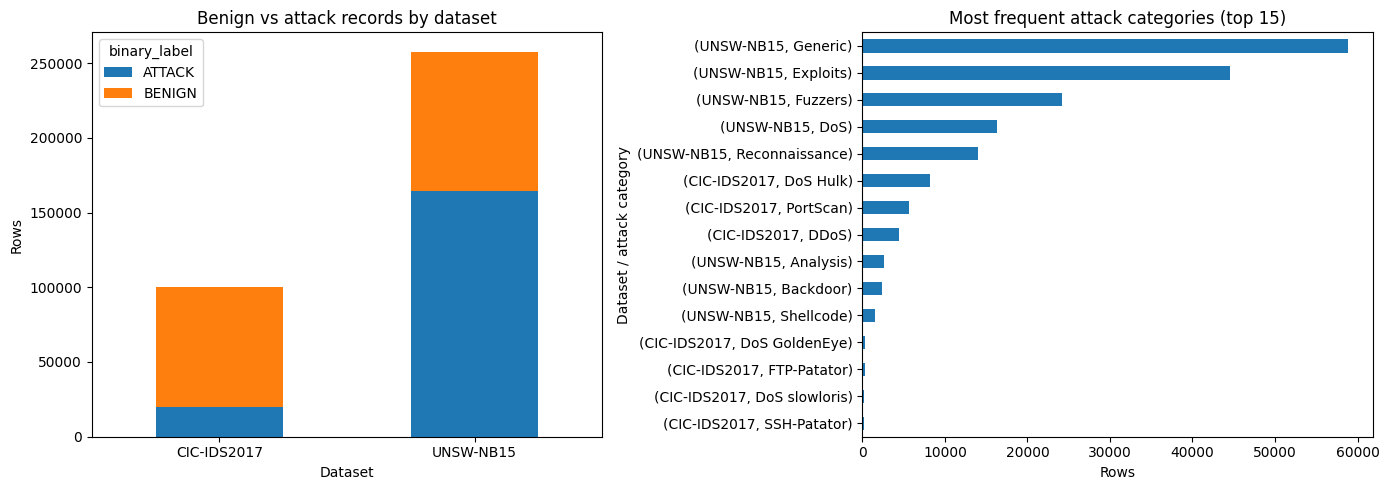


Class percentages within each dataset:


binary_label,ATTACK,BENIGN
dataset_source,,
CIC-IDS2017,19.74,80.26
UNSW-NB15,63.91,36.09



Saved Task 1 outputs to: /content/day1_task1_task2


In [ ]:
audit_rows = []
for source, part in merged.groupby("dataset_source", sort=False):
    feature_frame = part[FEATURES]
    finite_array = feature_frame.to_numpy(dtype=float, na_value=np.nan)
    infinite_cells = int(infinite_cells_by_source.get(source, 0))
    audit_rows.append({
        "dataset_source": source,
        "rows_loaded_for_eda": int(len(part)),
        "aligned_features": len(FEATURES),
        "missing_or_invalid_feature_cells_after_inf_handling": int(feature_frame.isna().sum().sum()),
        "infinite_feature_cells": infinite_cells,
        "duplicate_feature_label_rows": int(part[FEATURES + ["is_attack"]].duplicated().sum()),
        "benign_rows": int((part["is_attack"] == 0).sum()),
        "attack_rows": int((part["is_attack"] == 1).sum()),
        "attack_percent": round(100 * float((part["is_attack"] == 1).mean()), 2),
    })

audit_report = pd.DataFrame(audit_rows)
print("Audit summary (CIC row count reflects the sample already loaded or sampled by this notebook):")
display(audit_report)

print("\nBinary label counts by source:")
display(pd.crosstab(merged["dataset_source"], merged["binary_label"]))

print("\nOriginal attack-category counts by source (top 15 rows):")
category_counts = (
    merged.groupby(["dataset_source", "attack_category"]).size()
    .rename("rows").reset_index()
    .sort_values("rows", ascending=False)
)
display(category_counts.head(15))

# Apply only transparent data-quality fixes needed for EDA: numeric coercion was already done,
# and infinite values were replaced with missing values. Keep an explicit row-drop count.
rows_before = len(merged)
merged_clean = merged.dropna(subset=FEATURES + ["is_attack"]).copy()
rows_after = len(merged_clean)
print(f"\nRows before removing records with missing aligned features: {rows_before:,}")
print(f"Rows after cleaning: {rows_after:,}")
print(f"Rows removed for missing/infinite aligned features: {rows_before - rows_after:,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
label_counts_by_source = pd.crosstab(merged_clean["dataset_source"], merged_clean["binary_label"])
label_counts_by_source.plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_title("Benign vs attack records by dataset")
axes[0].set_xlabel("Dataset")
axes[0].set_ylabel("Rows")
axes[0].tick_params(axis="x", rotation=0)

attack_categories = merged_clean[merged_clean["is_attack"] == 1].groupby(
    ["dataset_source", "attack_category"]
).size().sort_values(ascending=False).head(15)
if not attack_categories.empty:
    attack_categories.sort_values().plot(kind="barh", ax=axes[1])
    axes[1].set_title("Most frequent attack categories (top 15)")
    axes[1].set_xlabel("Rows")
    axes[1].set_ylabel("Dataset / attack category")
else:
    axes[1].set_title("No attack categories available in the sample")
plt.tight_layout()
plt.show()

print("\nClass percentages within each dataset:")
display((pd.crosstab(merged_clean["dataset_source"], merged_clean["binary_label"], normalize="index") * 100).round(2))

# Save artifacts for the Day 1 report. The combined CSV contains normalized features, labels, and source.
output_dir = Path("/content/day1_task1_task2")
output_dir.mkdir(parents=True, exist_ok=True)
audit_report.to_csv(output_dir / "task1_dataset_audit_summary.csv", index=False)
category_counts.to_csv(output_dir / "task1_attack_category_counts.csv", index=False)
merged_clean.to_csv(output_dir / "task1_merged_eda_sample.csv", index=False)
print(f"\nSaved Task 1 outputs to: {output_dir}")

## Task 2A: SOC problem definition (design + documentation)

In [ ]:
SOC_SPEC = {
    "title": "SOC Problem Definition: Multi-dataset Network Intrusion Triage",
    "problem_statement": (
        "Security Operations Center analysts need a reproducible way to examine labeled network-flow "
        "records, distinguish benign from attack-like behavior, and prioritize suspicious flows for human review. "
        "This Day 1 work defines the problem and the expected triage contract; it does not claim a trained or live IDS."
    ),
    "primary_user": "SOC analyst / security monitoring team",
    "unit_of_analysis": "one labeled network-flow record",
    "data_sources": ["CIC-IDS2017", "UNSW-NB15"],
    "initial_prediction_target": "binary: BENIGN (0) vs ATTACK (1)",
    "candidate_shared_features": FEATURES,
    "expected_output": ["binary prediction", "optional attack probability from a future trained model", "triage priority", "dataset source for auditability"],
    "triage_policy": {
        "low_priority_if_probability_below": 0.50,
        "review_if_probability_at_least": 0.50,
        "high_priority_if_probability_at_least": 0.85,
        "status": "provisional demonstration thresholds; not calibrated or validated"
    },
    "success_metrics": [
        "attack recall / detection rate", "attack precision", "F1-score", "confusion matrix",
        "false-negative count", "false-positive count", "per-dataset results"
    ],
    "safety_and_scope": [
        "This is an offline benchmark/EDA exercise, not a production SOC deployment.",
        "An alert is a lead for investigation, not proof that an incident occurred.",
        "Do not automatically block traffic based on this Day 1 policy.",
        "Feature definitions may differ across dataset generations; harmonized features are approximate semantic matches.",
        "Keep dataset source visible and evaluate per source to expose domain shift.",
        "Preserve official train/test boundaries for future model evaluation; do not claim results from EDA as model performance."
    ]
}

print(json.dumps(SOC_SPEC, indent=2))

{
  "title": "SOC Problem Definition: Multi-dataset Network Intrusion Triage",
  "problem_statement": "Security Operations Center analysts need a reproducible way to examine labeled network-flow records, distinguish benign from attack-like behavior, and prioritize suspicious flows for human review. This Day 1 work defines the problem and the expected triage contract; it does not claim a trained or live IDS.",
  "primary_user": "SOC analyst / security monitoring team",
  "unit_of_analysis": "one labeled network-flow record",
  "data_sources": [
    "CIC-IDS2017",
    "UNSW-NB15"
  ],
  "initial_prediction_target": "binary: BENIGN (0) vs ATTACK (1)",
  "candidate_shared_features": [
    "flow_duration_seconds",
    "src_packets",
    "dst_packets",
    "src_bytes",
    "dst_bytes",
    "src_mean_packet_bytes",
    "dst_mean_packet_bytes"
  ],
  "expected_output": [
    "binary prediction",
    "optional attack probability from a future trained model",
    "triage priority",
    "dataset 

## Task 2B: Implement a simple alert-triage contract

In [ ]:
def triage_alert(prob_attack, review_threshold=0.50, high_threshold=0.85):
    """Convert a future model's attack score into a review priority.

    This is a policy scaffold only. The thresholds are provisional and are not model confidence
    until a calibrated model has been trained and evaluated.
    """
    try:
        score = float(prob_attack)
        review = float(review_threshold)
        high = float(high_threshold)
    except (TypeError, ValueError) as exc:
        raise ValueError("Scores and thresholds must be numeric.") from exc

    if not np.isfinite(score) or not 0.0 <= score <= 1.0:
        raise ValueError("prob_attack must be a finite value between 0 and 1.")
    if not (np.isfinite(review) and np.isfinite(high) and 0.0 <= review < high <= 1.0):
        raise ValueError("Thresholds must satisfy 0 <= review_threshold < high_threshold <= 1.")

    if score >= high:
        return "HIGH_PRIORITY_REVIEW"
    if score >= review:
        return "REVIEW"
    return "LOW_PRIORITY"

# Example policy demonstration only; these scores are synthetic, not predictions from a trained model.
example_scores = [0.12, 0.63, 0.93]
for score in example_scores:
    print(f"Example score={score:.2f} -> {triage_alert(score)}")

Example score=0.12 -> LOW_PRIORITY
Example score=0.63 -> REVIEW
Example score=0.93 -> HIGH_PRIORITY_REVIEW


## Task 2C: Test the SOC triage policy

In [ ]:
# Happy-path tests
assert triage_alert(0.10) == "LOW_PRIORITY"
assert triage_alert(0.50) == "REVIEW"
assert triage_alert(0.84) == "REVIEW"
assert triage_alert(0.85) == "HIGH_PRIORITY_REVIEW"
assert triage_alert(1.00) == "HIGH_PRIORITY_REVIEW"

# Invalid scores must be rejected rather than silently interpreted.
for invalid_score in [None, np.nan, np.inf, -0.01, 1.01, "not-a-number"]:
    try:
        triage_alert(invalid_score)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Expected ValueError for invalid score: {invalid_score!r}")

# Invalid threshold configuration must also be rejected.
for review, high in [(0.9, 0.8), (-0.1, 0.8), (0.2, 1.2), (0.5, 0.5)]:
    try:
        triage_alert(0.6, review_threshold=review, high_threshold=high)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Expected ValueError for invalid thresholds: {review}, {high}")

print("PASS: SOC triage policy tests")
print("Coverage: low-priority, review, high-priority, invalid scores, invalid thresholds")

PASS: SOC triage policy tests
Coverage: low-priority, review, high-priority, invalid scores, invalid thresholds


## Task 2D: Write the SOC problem statement and machine-readable specification

In [ ]:
(output_dir / "task2_soc_problem_statement.md").write_text(f"""# SOC Problem Definition: Multi-dataset Network Intrusion Triage

## Problem
Security Operations Center analysts must review large volumes of network traffic. The goal of this project is to examine labeled network-flow records and develop a reproducible process for identifying attack-like flows and prioritizing them for analyst review.

## Scope for this stage
This stage covers offline dataset analysis and the definition/testing of an alert-triage contract. It does not claim that a trained model or a live IDS is complete.

## Data
- CIC-IDS2017: current notebook sample: {len(cic_common):,} labeled rows used here.
- UNSW-NB15: loaded train + test rows for descriptive EDA: {len(unsw_common):,}.
- A merged, harmonized EDA table is written to `task1_merged_eda_sample.csv`.
- The two original schemas are not identical. Seven direction-aware flow features are aligned by meaning; all raw columns are not blindly concatenated.

## Initial target
Binary classification: `BENIGN` (0) versus `ATTACK` (1). The original attack category and dataset source are retained for analysis.

## Inputs and outputs
Inputs are flow duration, directional packet counts, directional bytes, and directional mean packet sizes. The intended future output is a benign/attack prediction plus a score and a triage priority. At present, the triage function is tested using synthetic example scores only.

## Provisional triage policy
- score below 0.50: `LOW_PRIORITY`
- score from 0.50 to below 0.85: `REVIEW`
- score at least 0.85: `HIGH_PRIORITY_REVIEW`

These are demonstration thresholds, not calibrated model thresholds. They must be tuned and validated against a held-out dataset before operational use.

## Evaluation criteria for a later model
Report attack recall, precision, F1-score, confusion matrix, false negatives, false positives, and results separately by dataset. Accuracy alone is insufficient when class distributions differ.

## Limitations and safeguards
1. An alert is a signal for investigation, not proof of an attack.
2. Do not automatically block traffic from this prototype.
3. Dataset features may be generated by different tools and have different distributions even when their meanings appear similar.
4. Preserve the official train/test split for future evaluation and do not use the combined EDA table as a leakage-prone train/test split.
5. This analysis is based on the existing CIC sample in the notebook (or a shuffled sample if loaded here), so CIC counts do not necessarily represent the complete CIC-IDS2017 dataset.

## Dataset references
- CIC-IDS2017: https://huggingface.co/datasets/bvsam/cic-ids-2017
- UNSW-NB15 mirror: https://huggingface.co/datasets/lacg030175/UNSW-NB15
- Official UNSW-NB15 page: https://research.unsw.edu.au/projects/unsw-nb15-dataset
""", encoding="utf-8")

(output_dir / "task2_soc_spec.json").write_text(json.dumps(SOC_SPEC, indent=2), encoding="utf-8")

(output_dir / "task1_data_sources_and_method.md").write_text(f"""# Task 1: Dataset Setup & EDA Notes

## Sources used
- CIC-IDS2017: {CIC_LOAD_NOTE}
- UNSW-NB15: official-style temporal train/test partition via the `lacg030175/UNSW-NB15` Hugging Face mirror.

## Row counts in this EDA run
- CIC aligned rows before missing-feature cleaning: {len(cic_common):,}
- UNSW aligned rows before missing-feature cleaning: {len(unsw_common):,}
- Merged aligned rows before missing-feature cleaning: {len(merged):,}
- Merged rows after missing-feature cleaning: {len(merged_clean):,}

## Shared feature mapping
- duration: CIC `Flow Duration` (microseconds, converted to seconds) ↔ UNSW `dur` (seconds)
- source packets: CIC `Total Fwd Packets` ↔ UNSW `spkts`
- destination packets: CIC `Total Backward Packets` ↔ UNSW `dpkts`
- source bytes: CIC `Total Length of Fwd Packets` ↔ UNSW `sbytes`
- destination bytes: CIC `Total Length of Bwd Packets` ↔ UNSW `dbytes`
- source mean packet size: CIC `Fwd Packet Length Mean` ↔ UNSW `smeansz` (or `smean` in some variants)
- destination mean packet size: CIC `Bwd Packet Length Mean` ↔ UNSW `dmeansz` (or `dmean` in some variants)

These are semantically aligned concepts, not a guarantee that the original feature-generation methods are identical.

## Cleaning applied
- target rows without valid labels were excluded during harmonization;
- numeric features were converted with invalid values becoming missing;
- positive/negative infinity values were converted to missing;
- rows with missing values in the seven aligned model-input features or target were excluded from the cleaned EDA table;
- dataset source and original target labels were preserved.

## Important split note
The UNSW train/test splits are combined only for descriptive Day 1 EDA. Keep their split identity in later model evaluation. Do not use this merged EDA table to claim model performance.
""", encoding="utf-8")

print("Wrote:")
for p in sorted(output_dir.iterdir()):
    print(f"- {p.name} ({p.stat().st_size:,} bytes)")

Wrote:
- task1_attack_category_counts.csv (644 bytes)
- task1_data_sources_and_method.md (1,906 bytes)
- task1_dataset_audit_summary.csv (293 bytes)
- task1_merged_eda_sample.csv (23,539,507 bytes)
- task2_soc_problem_statement.md (2,759 bytes)
- task2_soc_spec.json (2,084 bytes)


## Task 1 + Task 2 acceptance check

Before reporting completion, confirm that you have:

- [ ] Actual dataset row counts and the source of the CIC sample recorded.
- [ ] Missing values, infinite values, duplicate counts, and label distribution reviewed.
- [ ] Combined EDA table created only after the seven features were harmonized.
- [ ] SOC objective, intended user, input/output, metrics, limitations, and safeguards documented.
- [ ] Triage-policy tests passed.
- [ ] The saved report files reviewed and downloaded from Colab.

**Do not report an ML model accuracy yet.** This notebook does not train a model.

# DAY 2

## Task 3 + Task 4 + Task 5: Preprocessing pipeline, classifiers, and evaluation

**Goal:** train the first models on the seven harmonized flow features from Day 1 and measure them on held-out data.

- **Task 3: Reusable Preprocessing Pipeline**: one scikit-learn `Pipeline` that cleans, log-transforms, and scales the features. It is fitted on training data only.
- **Task 4: Baseline and Improved Classifiers**: a **random classifier** (`DummyClassifier`) first, then `LogisticRegression` (unweighted, then with balanced class weights), then `RandomForestClassifier`, all behind the same preprocessing.
- **Task 5: Model Evaluation & Artifact Export**: confusion matrix, accuracy, precision, recall, and F1 (overall and per dataset), followed by saving the fitted pipelines, metrics, predictions, and report files.

> **Run all Day 1 cells first.** Day 2 reuses `SEED`, `FEATURES`, `harmonize_unsw`, `cic_common`, `unsw_train_raw`, `unsw_test_raw`, `triage_alert`, and `output_dir`.

## Task 3A: Design the reusable preprocessing pipeline

**Input contract:** a DataFrame containing the seven harmonized columns in `FEATURES`, as produced by `harmonize_cic` / `harmonize_unsw`. Extra columns such as `dataset_source`, `is_attack`, or `original_label` are dropped by the pipeline, so labels cannot leak into the model inputs.

| Step | scikit-learn component | Why |
|---|---|---|
| 1. Select features | `ColumnTransformer(..., remainder="drop")` | Picks the 7 features by name; column order and extra columns do not matter. |
| 2. Infinity → missing | `FunctionTransformer(np.nan_to_num, ...)` | Flow statistics can contain ±inf, and `SimpleImputer` cannot handle infinity. |
| 3. Fill missing values | `SimpleImputer(strategy="median")` | The median is robust to heavy-tailed flow features. It is learned from training data only. |
| 4. Clip negatives to 0 | `FunctionTransformer(np.clip, ...)` | Durations, packet counts, and byte counts cannot be negative. CIC contains a few negative recording artefacts. |
| 5. Log transform | `FunctionTransformer(np.log1p)` | Bytes and packets span many orders of magnitude; `log1p` compresses the tails so a linear model can use them. |
| 6. Standardize | `StandardScaler()` | Zero mean and unit variance per feature, learned from training data only. |

**Train/test split (no leakage):**
- **UNSW-NB15:** keep the official train/test partition loaded on Day 1 (`unsw_train_raw` / `unsw_test_raw`).
- **CIC-IDS2017:** the Hugging Face sample has no official split, so use a stratified 80/20 random split with `SEED`.
- The training parts of both datasets are combined for fitting. The test parts are combined for evaluation, and each dataset is also scored separately.
- Every learned value (medians, means, standard deviations, model weights) comes from the training split only, because the preprocessing lives inside the model `Pipeline`.

Day 2 starts from the harmonized frames rather than `merged_clean`. Rows with missing or infinite features are kept and repaired by the pipeline instead of being dropped.

Only NumPy functions are used inside `FunctionTransformer`, so the saved pipelines can be loaded with `joblib` in a fresh Python session without re-running this notebook.

## Task 3B: Implement the preprocessing pipeline and the train/test split

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

TARGET = "is_attack"


def build_preprocessor(features=FEATURES):
    """Return an unfitted preprocessing transformer for the harmonized flow features."""
    numeric_steps = Pipeline(steps=[
        # SimpleImputer rejects infinity, so turn +/-inf into NaN first.
        ("inf_to_nan", FunctionTransformer(
            np.nan_to_num,
            kw_args={"nan": np.nan, "posinf": np.nan, "neginf": np.nan},
            feature_names_out="one-to-one",
        )),
        ("impute_median", SimpleImputer(strategy="median")),
        # Durations, packet counts and byte counts cannot be negative.
        ("clip_negative", FunctionTransformer(
            np.clip,
            kw_args={"a_min": 0, "a_max": None},
            feature_names_out="one-to-one",
        )),
        # Flow features are heavy-tailed; log1p compresses very large values.
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer(
        transformers=[("flow_features", numeric_steps, list(features))],
        remainder="drop",
        verbose_feature_names_out=False,
    )


# CIC-IDS2017: no official split in the Hugging Face sample, so use a stratified 80/20 split.
cic_train, cic_test = train_test_split(
    cic_common, test_size=0.20, stratify=cic_common[TARGET], random_state=SEED,
)
# UNSW-NB15: keep the official train/test boundary.
unsw_train = harmonize_unsw(unsw_train_raw)
unsw_test = harmonize_unsw(unsw_test_raw)

train_df = pd.concat([cic_train, unsw_train], ignore_index=True)
test_df = pd.concat([cic_test, unsw_test], ignore_index=True)

X_train, y_train = train_df[FEATURES], train_df[TARGET].astype(int)
X_test, y_test = test_df[FEATURES], test_df[TARGET].astype(int)

split_summary = (
    pd.concat([train_df.assign(split="train"), test_df.assign(split="test")])
    .groupby(["dataset_source", "split"], sort=False)
    .agg(rows=(TARGET, "size"), attack_rows=(TARGET, "sum"), attack_percent=(TARGET, "mean"))
)
split_summary["attack_percent"] = (split_summary["attack_percent"] * 100).round(2)
print("Train/test split by dataset:")
display(split_summary)

raw_train_values = X_train.to_numpy(dtype=float)
print("Raw training cells that are missing or infinite:", int((~np.isfinite(raw_train_values)).sum()))
print("Raw training cells that are negative:", int((raw_train_values < 0).sum()))

preprocessor = build_preprocessor().fit(X_train)
X_train_prepared = preprocessor.transform(X_train)
print("\nPrepared training matrix:", X_train_prepared.shape)
print("Non-finite values after preprocessing:", int((~np.isfinite(X_train_prepared)).sum()))
display(
    pd.DataFrame(X_train_prepared, columns=preprocessor.get_feature_names_out())
    .describe().T[["mean", "std", "min", "max"]].round(3)
)

Train/test split by dataset:


,,rows,attack_rows,attack_percent
dataset_source,split,,,
CIC-IDS2017,train,80000,15790,19.74
UNSW-NB15,train,175341,119341,68.06
CIC-IDS2017,test,20000,3947,19.74
UNSW-NB15,test,82332,45332,55.06


Raw training cells that are missing or infinite: 0
Raw training cells that are negative: 4

Prepared training matrix: (255341, 7)
Non-finite values after preprocessing: 0


,mean,std,min,max
flow_duration_seconds,0.0,1.0,-0.482,3.876
src_packets,0.0,1.0,-1.051,9.621
dst_packets,-0.0,1.0,-0.949,8.084
src_bytes,0.0,1.0,-2.493,4.907
dst_bytes,-0.0,1.0,-1.056,4.292
src_mean_packet_bytes,0.0,1.0,-3.012,3.336
dst_mean_packet_bytes,0.0,1.0,-1.098,2.105


## Task 3C: Test the preprocessing pipeline

In [ ]:
from sklearn.base import clone

# 1. Messy input (NaN, +/-inf, negative) must come out finite, with one column per feature.
messy = X_train.head(5).astype(float).copy()
messy.iloc[0, 0] = np.nan
messy.iloc[1, 1] = np.inf
messy.iloc[2, 2] = -np.inf
messy.iloc[3, 3] = -50.0
messy_before = messy.copy()
messy_out = preprocessor.transform(messy)
assert messy_out.shape == (len(messy), len(FEATURES))
assert np.isfinite(messy_out).all(), "Preprocessing must remove NaN and infinity"

# 2. The caller's DataFrame is not modified in place.
pd.testing.assert_frame_equal(messy, messy_before)

# 3. Extra columns (including the label) are ignored, and column order does not matter.
with_extras = messy.assign(is_attack=1, dataset_source="TEST")[["is_attack", "dataset_source"] + FEATURES[::-1]]
np.testing.assert_allclose(preprocessor.transform(with_extras), messy_out)

# 4. Missing and infinite values are filled with the TRAINING median (fit on train only).
imputer = preprocessor.named_transformers_["flow_features"].named_steps["impute_median"]
train_medians = X_train.replace([np.inf, -np.inf], np.nan).median().to_numpy()
np.testing.assert_allclose(imputer.statistics_, train_medians)

# 5. A negative value is clipped to 0, so it gives the same output as an exact 0.
zero_row = messy.iloc[[3]].copy()
zero_row.iloc[0, 3] = 0.0
np.testing.assert_allclose(preprocessor.transform(zero_row), messy_out[[3]])

# 6. Standardized training features have mean ~0 and standard deviation ~1.
np.testing.assert_allclose(X_train_prepared.mean(axis=0), 0, atol=1e-6)
np.testing.assert_allclose(X_train_prepared.std(axis=0), 1, atol=1e-6)

# 7. Re-fitting a fresh, unfitted copy gives identical results (deterministic).
np.testing.assert_allclose(clone(preprocessor).fit(X_train).transform(messy), messy_out)

# 8. Split integrity: no CIC row in both splits, UNSW official split sizes kept, both classes present.
assert set(cic_train.index).isdisjoint(cic_test.index)
assert len(cic_train) + len(cic_test) == len(cic_common)
assert len(unsw_train) == len(unsw_train_raw) and len(unsw_test) == len(unsw_test_raw)
for split_name, split_frame in [("train", train_df), ("test", test_df)]:
    for source, part in split_frame.groupby("dataset_source"):
        assert part[TARGET].nunique() == 2, f"{source} {split_name} split must contain both classes"

print("PASS: preprocessing pipeline tests")
print("Coverage: NaN/inf/negative handling, no input mutation, extra and reordered columns, "
      "train-only imputation, clipping, scaling, determinism, split integrity")

PASS: preprocessing pipeline tests
Coverage: NaN/inf/negative handling, no input mutation, extra and reordered columns, train-only imputation, clipping, scaling, determinism, split integrity


## Task 3D: Document the preprocessing pipeline

- **What it is:** `build_preprocessor()` returns an unfitted scikit-learn `ColumnTransformer`: 7 harmonized features → infinity to NaN → median imputation → clip negatives to 0 → `log1p` → standardize.
- **How to reuse it:** wrap any classifier with `build_model_pipeline(classifier)` (Task 4), fit on a training frame, then call `.predict()` / `.predict_proba()` on any DataFrame that has the `FEATURES` columns, for example `harmonize_unsw(new_raw_frame)`.
- **Leakage guard:** all statistics are learned in `.fit()` on the training split only. The test split is only passed to `.transform()`, `.predict()`, and `.predict_proba()`.
- **Tests (Task 3C):** messy values, input not modified, extra or reordered columns, train-only medians, clipping, scaling, determinism, and split integrity.
- **Limitations:** clipping negatives to 0 assumes they are recording errors. The CIC split is random, not time-based, and identical flows can appear in both CIC train and CIC test (Day 1 counted these duplicates), so CIC scores may be optimistic.

The same description is written to `task3_preprocessing_pipeline.md` in Task 5D.

## Task 4A: Design the baseline and improved classifiers

All four models use the same `Pipeline(preprocess → classifier)`, so the classifier is the only thing that changes.

| Role | Model | Why |
|---|---|---|
| Baseline | `DummyClassifier(strategy="stratified")` | A **random classifier**: it ignores the features and guesses ATTACK at the training attack rate. It sets the "no skill" floor that any real model must beat. |
| Improved (linear) | `LogisticRegression(max_iter=1000)` | A simple, fast, interpretable linear model. It also outputs an attack probability, which the Day 1 `triage_alert` policy needs. |
| Improved (linear, weighted) | `LogisticRegression(max_iter=1000, class_weight="balanced")` | The same linear model, but each training row is weighted by `n_rows / (2 × rows in its class)`, so BENIGN and ATTACK count equally in the loss and the model cannot simply lean towards the more common class. How much this changes depends on how imbalanced the training data is; Task 4B prints the actual weights. |
| Improved (non-linear) | `RandomForestClassifier(n_estimators=100, min_samples_leaf=5)` | An ensemble of 100 decision trees. It can learn non-linear rules and feature interactions that a linear model misses, and it also outputs an attack probability. `min_samples_leaf=5` keeps the saved model to tens of MB instead of over 100 MB, with almost no loss in F1. |

- **Target:** `is_attack` (0 = BENIGN, 1 = ATTACK). ATTACK is the positive class for precision, recall, and F1.
- **Training data:** the combined CIC + UNSW training split from Task 3. No test rows are used in fitting.
- **Preprocessing and trees:** the log transform and scaling neither help nor hurt a random forest, because trees only use the order of values. Sharing one pipeline keeps the comparison fair and the saved models consistent.
- **Reproducibility:** all models use `random_state=SEED`.

## Task 4B: Implement and train the classifiers

In [ ]:
import time

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight


def build_model_pipeline(classifier, features=FEATURES):
    """Attach a classifier to a fresh, unfitted copy of the preprocessing pipeline."""
    return Pipeline(steps=[
        ("preprocess", build_preprocessor(features)),
        ("classifier", classifier),
    ])


MODELS = {
    "random_baseline": build_model_pipeline(DummyClassifier(strategy="stratified", random_state=SEED)),
    "logistic_regression": build_model_pipeline(LogisticRegression(max_iter=1000, random_state=SEED)),
    "logistic_regression_weighted": build_model_pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
    ),
    "random_forest": build_model_pipeline(RandomForestClassifier(
        n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED,
    )),
}
LOGREG_MODELS = ["logistic_regression", "logistic_regression_weighted"]
# Models whose predict_proba is a real attack score (the random baseline's is just its random guess).
IMPROVED_MODELS = LOGREG_MODELS + ["random_forest"]

# class_weight="balanced" weights each class by n_rows / (2 * rows in that class).
balanced_weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
print(f"Training attack rate: {y_train.mean():.2%}")
print(f"Balanced class weights used by logistic_regression_weighted: "
      f"BENIGN = {balanced_weights[0]:.3f}, ATTACK = {balanced_weights[1]:.3f}\n")

for name, model in MODELS.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    print(f"Trained {name} on {len(X_train):,} training rows in {time.perf_counter() - start:.1f}s")

# Weights on the log-scaled, standardized features: positive values push a flow towards ATTACK.
logreg = MODELS["logistic_regression"]
lr_coefficients = pd.DataFrame(
    {name: MODELS[name].named_steps["classifier"].coef_[0] for name in LOGREG_MODELS},
    index=logreg.named_steps["preprocess"].get_feature_names_out(),
).sort_values("logistic_regression")
print("\nLogistic regression coefficients (unweighted vs class-weighted):")
display(lr_coefficients.round(3))
for name in LOGREG_MODELS:
    print(f"Intercept ({name}): {MODELS[name].named_steps['classifier'].intercept_[0]:.3f}")

# Random forest: share of the trees' total impurity reduction from each feature (sums to 1, no direction).
forest = MODELS["random_forest"]
rf_importances = pd.Series(
    forest.named_steps["classifier"].feature_importances_,
    index=forest.named_steps["preprocess"].get_feature_names_out(),
    name="importance",
).sort_values(ascending=False)
print("\nRandom forest feature importances:")
display(rf_importances.round(3).to_frame())

Training attack rate: 52.92%
Balanced class weights used by logistic_regression_weighted: BENIGN = 1.062, ATTACK = 0.945

Trained random_baseline on 255,341 training rows in 0.5s
Trained logistic_regression on 255,341 training rows in 2.0s
Trained logistic_regression_weighted on 255,341 training rows in 1.7s
Trained random_forest on 255,341 training rows in 29.2s

Logistic regression coefficients (unweighted vs class-weighted):


,logistic_regression,logistic_regression_weighted
dst_mean_packet_bytes,-8.960,-8.943
dst_packets,-5.404,-5.401
src_mean_packet_bytes,-4.495,-4.440
src_packets,-3.491,-3.471
flow_duration_seconds,0.198,0.190
src_bytes,7.312,7.260
dst_bytes,12.191,12.177


Intercept (logistic_regression): 0.157
Intercept (logistic_regression_weighted): 0.041

Random forest feature importances:


,importance
flow_duration_seconds,0.261
src_bytes,0.152
dst_mean_packet_bytes,0.138
src_mean_packet_bytes,0.136
dst_bytes,0.119
dst_packets,0.115
src_packets,0.079


## Task 4C: Test the classifiers

In [ ]:
from sklearn.metrics import f1_score

for name, model in MODELS.items():
    preds = model.predict(X_test)
    assert preds.shape == (len(X_test),), f"{name}: one prediction per test row"
    assert set(np.unique(preds)) <= {0, 1}, f"{name}: predictions must be 0 or 1"
    assert list(model.classes_) == [0, 1], f"{name}: predict_proba column 1 must be ATTACK"
    proba = model.predict_proba(X_test)
    assert proba.shape == (len(X_test), 2)
    assert ((proba >= 0) & (proba <= 1)).all() and np.allclose(proba.sum(axis=1), 1.0)

# The random baseline is reproducible and guesses ATTACK at about the training attack rate.
baseline = MODELS["random_baseline"]
baseline_preds = baseline.predict(X_test)
np.testing.assert_array_equal(baseline_preds, baseline.predict(X_test))
assert abs(baseline_preds.mean() - y_train.mean()) < 0.01

# Each model pipeline's preprocessing matches the standalone preprocessor fitted in Task 3B.
for name in IMPROVED_MODELS:
    np.testing.assert_allclose(
        MODELS[name].named_steps["preprocess"].transform(X_test.head(1_000)),
        preprocessor.transform(X_test.head(1_000)),
    )

# The weighted model really uses balanced class weights, and they shift it towards the class that is
# rarer in training: it predicts that class at least as often as the unweighted model does.
assert MODELS["logistic_regression_weighted"].named_steps["classifier"].class_weight == "balanced"
assert MODELS["logistic_regression"].named_steps["classifier"].class_weight is None
np.testing.assert_allclose(balanced_weights * np.bincount(y_train), len(y_train) / 2)
minority_class = 0 if y_train.mean() > 0.5 else 1
minority_rate = {name: (MODELS[name].predict(X_test) == minority_class).mean() for name in LOGREG_MODELS}
assert minority_rate["logistic_regression_weighted"] >= minority_rate["logistic_regression"], minority_rate

# The random forest's feature importances cover every feature and sum to 1.
assert sorted(rf_importances.index) == sorted(FEATURES)
assert np.isclose(rf_importances.sum(), 1.0)

# Every improved model must beat random guessing.
f1_baseline = f1_score(y_test, baseline_preds)
f1_improved = {name: f1_score(y_test, MODELS[name].predict(X_test)) for name in IMPROVED_MODELS}
for name, f1 in f1_improved.items():
    assert f1 > f1_baseline, f"{name} must beat the random baseline on F1"

print("PASS: classifier tests")
print(f"Test F1 - random baseline: {f1_baseline:.4f}, "
      + ", ".join(f"{name}: {f1:.4f}" for name, f1 in f1_improved.items()))

PASS: classifier tests
Test F1 - random baseline: 0.5029, logistic_regression: 0.7200, logistic_regression_weighted: 0.6944, random_forest: 0.8912


## Task 4D: Document the classifiers

- **Random baseline (`DummyClassifier`, stratified):** ignores the flow features and predicts ATTACK at random, at the training attack rate. Its precision is about the share of attacks in the test data, and its recall is about the training attack rate. Those numbers mean "no skill".
- **Logistic regression:** a linear model on the 7 log-scaled, standardized features. It outputs `P(ATTACK)`, so its scores can be passed to `triage_alert`. Coefficients are printed in Task 4B: positive weights push a flow towards ATTACK.
- **Logistic regression with class weights:** the same model with `class_weight="balanced"`, so errors on the rarer class cost more during training. Expect it to predict the rarer class more often: fewer errors on that class, more on the other. Task 4B prints the weights and both sets of coefficients side by side.
- **Random forest:** 100 decision trees (`min_samples_leaf=5`), each trained on a bootstrap sample of the training rows. `P(ATTACK)` is the average of the trees' votes, so it can also be passed to `triage_alert`. Feature importances are printed in Task 4B: they show how much the trees rely on each feature, not whether it pushes towards ATTACK or BENIGN.
- **Fair comparison:** all four models share `build_model_pipeline`, the same training rows, and the same test rows. Task 5 reports them side by side.
- **Tests (Task 4C):** prediction shape and labels, valid probabilities, a reproducible baseline, preprocessing fitted on train only, correct balanced class weights and their effect, valid feature importances, and every improved model beating the baseline on F1.
- **Limitations:** the linear models draw one straight boundary through 7 features. All models are trained on both datasets, whose attack rates differ a lot, so they can partly learn "which dataset is this?" instead of attack behaviour. That is why Task 5 scores each dataset separately. Balanced class weights correct the BENIGN/ATTACK balance overall, not the imbalance between the two datasets. Probabilities are not calibrated, so the triage thresholds stay provisional.
- **Next steps (not done here):** weight each dataset × class group equally (via `sample_weight`), so the smaller CIC part counts as much as UNSW. Tune the random forest on a validation split taken from the training data, never on the test split.

The same description is written to `task4_classifiers.md` in Task 5D.

## Task 5A: Design the evaluation and artifact export

**Metrics (positive class = ATTACK):**

| Metric | Formula | SOC meaning |
|---|---|---|
| Accuracy | (TP + TN) / all | Share of all flows labelled correctly. Can be misleading when the classes are imbalanced. |
| Precision | TP / (TP + FP) | Of the flows we alert on, how many are real attacks (alert quality and analyst workload). |
| Recall | TP / (TP + FN) | Of the real attacks, how many we catch (detection rate). Missed attacks are the costly error. |
| F1-score | 2 · P · R / (P + R) | One number that balances precision and recall. |
| Confusion matrix | rows = true label, columns = predicted label | Exact TN, FP, FN, and TP counts. |

Every model is scored on the held-out test split for **ALL** rows, and separately for **CIC-IDS2017** and **UNSW-NB15**, as the Day 1 SOC spec requires.

**Artifacts written to `/content/day2_task3_task5/`:**
- `models/random_baseline.joblib`, `models/logistic_regression.joblib`, `models/logistic_regression_weighted.joblib`, and `models/random_forest.joblib` (tens of MB): full fitted pipelines (preprocessing + classifier)
- `task5_test_metrics.csv` and `task5_test_metrics.json`: every metric for every model and scope
- `task5_confusion_matrices.png`
- `task5_test_predictions.csv`: per-row predictions from every model, plus the attack probability and Day 1 triage priority from both logistic regressions and the random forest
- `day2_manifest.json`: features, split sizes, seed, and library versions needed to reload the models
- `task3_preprocessing_pipeline.md`, `task4_classifiers.md`, and `task5_evaluation_report.md`

## Task 5B: Evaluate the classifiers and export the artifacts

===== random_baseline: test set, all sources (102,332 rows) =====
Accuracy : 0.4975
Precision: 0.4803
Recall   : 0.5279
F1-score : 0.5029
Confusion matrix (rows = true label, columns = predicted label):


,pred BENIGN,pred ATTACK
true BENIGN,24902,28151
true ATTACK,23266,26013



===== logistic_regression: test set, all sources (102,332 rows) =====
Accuracy : 0.7066
Precision: 0.6661
Recall   : 0.7834
F1-score : 0.7200
Confusion matrix (rows = true label, columns = predicted label):


,pred BENIGN,pred ATTACK
true BENIGN,33704,19349
true ATTACK,10674,38605



===== logistic_regression_weighted: test set, all sources (102,332 rows) =====
Accuracy : 0.6992
Precision: 0.6798
Recall   : 0.7098
F1-score : 0.6944
Confusion matrix (rows = true label, columns = predicted label):


,pred BENIGN,pred ATTACK
true BENIGN,36575,16478
true ATTACK,14303,34976



===== random_forest: test set, all sources (102,332 rows) =====
Accuracy : 0.8859
Precision: 0.8238
Recall   : 0.9707
F1-score : 0.8912
Confusion matrix (rows = true label, columns = predicted label):


,pred BENIGN,pred ATTACK
true BENIGN,42818,10235
true ATTACK,1442,47837



All metrics, overall and per dataset:


,model,evaluated_on,rows,accuracy,precision,recall,f1,true_negatives,false_positives,false_negatives,true_positives
0,random_baseline,ALL,102332,0.4975,0.4803,0.5279,0.5029,24902,28151,23266,26013
1,random_baseline,CIC-IDS2017,20000,0.4818,0.1980,0.5328,0.2887,7533,8520,1844,2103
2,random_baseline,UNSW-NB15,82332,0.5014,0.5491,0.5274,0.5381,17369,19631,21422,23910
3,logistic_regression,ALL,102332,0.7066,0.6661,0.7834,0.7200,33704,19349,10674,38605
4,logistic_regression,CIC-IDS2017,20000,0.6698,0.1427,0.1345,0.1385,12864,3189,3416,531
5,logistic_regression,UNSW-NB15,82332,0.7156,0.7020,0.8399,0.7648,20840,16160,7258,38074
6,logistic_regression_weighted,ALL,102332,0.6992,0.6798,0.7098,0.6944,36575,16478,14303,34976
7,logistic_regression_weighted,CIC-IDS2017,20000,0.6750,0.1267,0.1097,0.1176,13068,2985,3514,433
8,logistic_regression_weighted,UNSW-NB15,82332,0.7051,0.7191,0.7620,0.7399,23507,13493,10789,34543
9,random_forest,ALL,102332,0.8859,0.8238,0.9707,0.8912,42818,10235,1442,47837


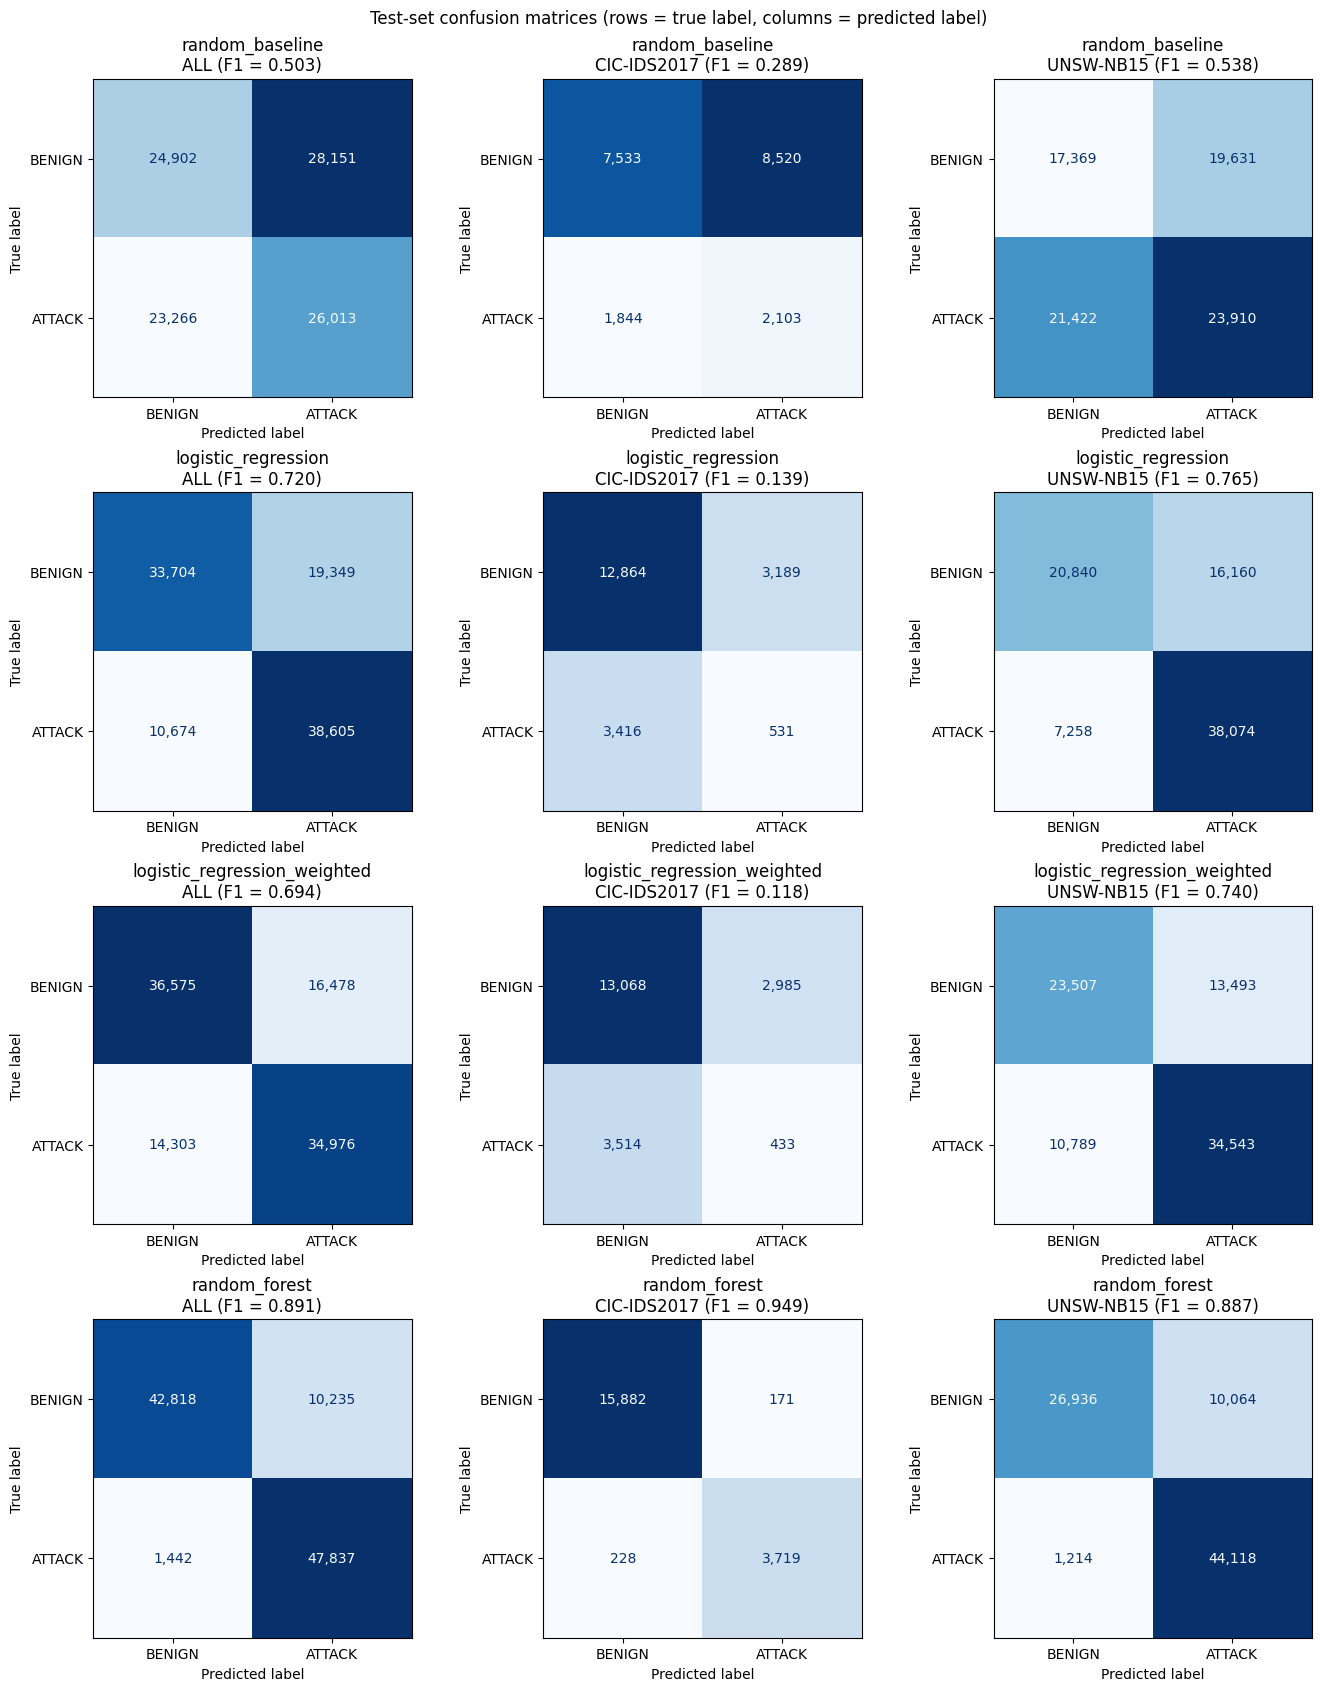

In [ ]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

CLASS_NAMES = ["BENIGN", "ATTACK"]
DAY2_OUTPUT_DIR = output_dir.parent / "day2_task3_task5"
MODEL_DIR = DAY2_OUTPUT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)


def evaluate_predictions(y_true, y_pred):
    """Accuracy, precision, recall, F1 and confusion-matrix counts, with ATTACK (1) as the positive class."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "rows": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
    }


def metrics_for(model_name, scope="ALL"):
    return metrics_df[(metrics_df["model"] == model_name) & (metrics_df["evaluated_on"] == scope)].iloc[0]


EVAL_SCOPES = {"ALL": np.ones(len(test_df), dtype=bool)}
for source in test_df["dataset_source"].unique():
    EVAL_SCOPES[source] = (test_df["dataset_source"] == source).to_numpy()

y_test_array = y_test.to_numpy()
test_predictions = {name: model.predict(X_test) for name, model in MODELS.items()}

metric_rows = []
for name, y_pred in test_predictions.items():
    for scope, mask in EVAL_SCOPES.items():
        metric_rows.append({"model": name, "evaluated_on": scope, **evaluate_predictions(y_test_array[mask], y_pred[mask])})
metrics_df = pd.DataFrame(metric_rows)

for name in MODELS:
    overall = metrics_for(name)
    print(f"===== {name}: test set, all sources ({overall['rows']:,} rows) =====")
    print(f"Accuracy : {overall['accuracy']:.4f}")
    print(f"Precision: {overall['precision']:.4f}")
    print(f"Recall   : {overall['recall']:.4f}")
    print(f"F1-score : {overall['f1']:.4f}")
    print("Confusion matrix (rows = true label, columns = predicted label):")
    display(pd.DataFrame(
        confusion_matrix(y_test_array, test_predictions[name], labels=[0, 1]),
        index=[f"true {c}" for c in CLASS_NAMES],
        columns=[f"pred {c}" for c in CLASS_NAMES],
    ))
    print()

print("All metrics, overall and per dataset:")
display(metrics_df.round(4))

fig, axes = plt.subplots(
    len(MODELS), len(EVAL_SCOPES), figsize=(4.5 * len(EVAL_SCOPES), 4.2 * len(MODELS)),
    squeeze=False, layout="constrained",  # constrained layout keeps the suptitle clear of the panel titles
)
for row, (name, y_pred) in enumerate(test_predictions.items()):
    for col, (scope, mask) in enumerate(EVAL_SCOPES.items()):
        ax = axes[row, col]
        ConfusionMatrixDisplay.from_predictions(
            y_test_array[mask], y_pred[mask],
            labels=[0, 1], display_labels=CLASS_NAMES,
            cmap="Blues", colorbar=False, values_format=",d", ax=ax,
        )
        ax.set_title(f"{name}\n{scope} (F1 = {metrics_for(name, scope)['f1']:.3f})")
fig.suptitle("Test-set confusion matrices (rows = true label, columns = predicted label)")
fig.savefig(DAY2_OUTPUT_DIR / "task5_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import platform

import joblib
import sklearn

# 1. Fitted pipelines: preprocessing + classifier in one file per model.
model_paths = {}
for name, model in MODELS.items():
    model_paths[name] = MODEL_DIR / f"{name}.joblib"
    joblib.dump(model, model_paths[name])

# 2. Metrics (the confusion-matrix figure was saved by the previous cell).
metrics_df.to_csv(DAY2_OUTPUT_DIR / "task5_test_metrics.csv", index=False)
(DAY2_OUTPUT_DIR / "task5_test_metrics.json").write_text(json.dumps(metric_rows, indent=2), encoding="utf-8")

# 3. Per-row test predictions from every model. For the improved models, also export the attack
#    probability and apply the Day 1 triage policy to it.
test_predictions_export = test_df[["dataset_source", "original_label", TARGET]].copy()
for name in MODELS:
    test_predictions_export[f"{name}_pred"] = test_predictions[name]

test_prob_attack, triage_counts = {}, {}
for name in IMPROVED_MODELS:
    test_prob_attack[name] = MODELS[name].predict_proba(X_test)[:, 1]
    test_predictions_export[f"{name}_prob_attack"] = test_prob_attack[name]
    test_predictions_export[f"{name}_triage"] = [triage_alert(p) for p in test_prob_attack[name]]
    triage_counts[name] = pd.crosstab(
        test_predictions_export[f"{name}_triage"],
        test_predictions_export[TARGET].map({0: "BENIGN", 1: "ATTACK"}),
    ).reindex(index=["LOW_PRIORITY", "REVIEW", "HIGH_PRIORITY_REVIEW"], columns=CLASS_NAMES, fill_value=0)
    print(f"Day 1 triage priority vs true label ({name}, test set):")
    display(triage_counts[name])
test_predictions_export.to_csv(DAY2_OUTPUT_DIR / "task5_test_predictions.csv", index=False)

# 4. Manifest: what someone needs to reload and trust the saved models.
DAY2_MANIFEST = {
    "features": FEATURES,
    "target": f"{TARGET} (0 = BENIGN, 1 = ATTACK)",
    "seed": SEED,
    "split": {
        "CIC-IDS2017": "stratified random 80/20 split of the notebook sample",
        "UNSW-NB15": "official temporal train/test partition",
        "train_rows": int(len(train_df)),
        "test_rows": int(len(test_df)),
    },
    "models": {name: path.relative_to(DAY2_OUTPUT_DIR).as_posix() for name, path in model_paths.items()},
    "library_versions": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
    },
    "load_example": "joblib.load('models/logistic_regression.joblib').predict_proba(frame[features])[:, 1]",
}
(DAY2_OUTPUT_DIR / "day2_manifest.json").write_text(json.dumps(DAY2_MANIFEST, indent=2), encoding="utf-8")

print(f"\nSaved Day 2 artifacts to: {DAY2_OUTPUT_DIR}")

Day 1 triage priority vs true label (logistic_regression, test set):


is_attack,BENIGN,ATTACK
logistic_regression_triage,,
LOW_PRIORITY,33704,10674
REVIEW,14829,9481
HIGH_PRIORITY_REVIEW,4520,29124


Day 1 triage priority vs true label (logistic_regression_weighted, test set):


is_attack,BENIGN,ATTACK
logistic_regression_weighted_triage,,
LOW_PRIORITY,36575,14303
REVIEW,15490,33762
HIGH_PRIORITY_REVIEW,988,1214


Day 1 triage priority vs true label (random_forest, test set):


is_attack,BENIGN,ATTACK
random_forest_triage,,
LOW_PRIORITY,42818,1442
REVIEW,8693,4657
HIGH_PRIORITY_REVIEW,1542,43180



Saved Day 2 artifacts to: /content/day2_task3_task5


## Task 5C: Test the evaluation and exported artifacts

In [ ]:
import subprocess
import sys

# 1. The metric helper matches hand-computed values on a tiny known example (TP=2, FN=1, FP=1, TN=1).
toy = evaluate_predictions(np.array([1, 1, 1, 0, 0]), np.array([1, 1, 0, 1, 0]))
assert (toy["true_positives"], toy["false_negatives"], toy["false_positives"], toy["true_negatives"]) == (2, 1, 1, 1)
assert np.isclose(toy["accuracy"], 3 / 5)
assert np.isclose(toy["precision"], 2 / 3) and np.isclose(toy["recall"], 2 / 3) and np.isclose(toy["f1"], 2 / 3)

# 2. Every expected file exists and is not empty.
assert sorted(model_paths) == sorted(MODELS)
expected_files = [
    *model_paths.values(),
    DAY2_OUTPUT_DIR / "task5_test_metrics.csv",
    DAY2_OUTPUT_DIR / "task5_test_metrics.json",
    DAY2_OUTPUT_DIR / "task5_confusion_matrices.png",
    DAY2_OUTPUT_DIR / "task5_test_predictions.csv",
    DAY2_OUTPUT_DIR / "day2_manifest.json",
]
for path in expected_files:
    assert path.exists() and path.stat().st_size > 0, f"Missing or empty artifact: {path}"

# 3. Reloaded pipelines reproduce the in-memory predictions (and probabilities) exactly.
for name, path in model_paths.items():
    reloaded = joblib.load(path)
    np.testing.assert_array_equal(reloaded.predict(X_test), test_predictions[name])
    if name in IMPROVED_MODELS:
        np.testing.assert_allclose(reloaded.predict_proba(X_test)[:, 1], test_prob_attack[name])

# 4. Every saved pipeline loads in a fresh Python process, without any functions from this notebook.
fresh_load = subprocess.run(
    [sys.executable, "-c", "import sys, joblib; print(*[type(joblib.load(p)).__name__ for p in sys.argv[1:]])",
     *map(str, model_paths.values())],
    capture_output=True, text=True,
)
assert fresh_load.returncode == 0 and fresh_load.stdout.split() == ["Pipeline"] * len(model_paths), fresh_load.stderr

# 5. Saved metrics are valid and internally consistent.
saved_metrics = pd.read_csv(DAY2_OUTPUT_DIR / "task5_test_metrics.csv")
count_cols = ["true_negatives", "false_positives", "false_negatives", "true_positives"]
assert saved_metrics[["accuracy", "precision", "recall", "f1"]].apply(lambda s: s.between(0, 1).all()).all()
assert (saved_metrics[count_cols].sum(axis=1) == saved_metrics["rows"]).all()
for m in saved_metrics.itertuples():
    expected_f1 = 0.0 if m.precision + m.recall == 0 else 2 * m.precision * m.recall / (m.precision + m.recall)
    assert np.isclose(m.f1, expected_f1)
    assert np.isclose(m.accuracy, (m.true_negatives + m.true_positives) / m.rows)

# 6. Per-dataset counts add up to the ALL counts for each model.
for name in MODELS:
    part = saved_metrics[saved_metrics["model"] == name].set_index("evaluated_on")
    per_source_total = part.drop(index="ALL")[["rows"] + count_cols].sum()
    assert (per_source_total == part.loc["ALL", ["rows"] + count_cols]).all(), name

# 7. Predictions file: one row per test row, a prediction column per model, and valid triage labels
#    that agree with each improved model's probability.
saved_predictions = pd.read_csv(DAY2_OUTPUT_DIR / "task5_test_predictions.csv")
assert len(saved_predictions) == len(test_df)
for name in MODELS:
    np.testing.assert_array_equal(saved_predictions[f"{name}_pred"], test_predictions[name])
for name in IMPROVED_MODELS:
    triage, prob = saved_predictions[f"{name}_triage"], saved_predictions[f"{name}_prob_attack"]
    assert set(triage) <= {"LOW_PRIORITY", "REVIEW", "HIGH_PRIORITY_REVIEW"}, name
    assert (prob[triage == "LOW_PRIORITY"] < 0.50).all() and (prob[triage != "LOW_PRIORITY"] >= 0.50).all(), name
    assert (prob[triage == "HIGH_PRIORITY_REVIEW"] >= 0.85).all(), name

# 8. The manifest lists the features the saved models expect.
saved_manifest = json.loads((DAY2_OUTPUT_DIR / "day2_manifest.json").read_text(encoding="utf-8"))
assert saved_manifest["features"] == FEATURES

print("PASS: evaluation and artifact export tests")
print("Coverage: metric formulas, files present, identical predictions after reload, fresh-process load, "
      "metric consistency, per-dataset totals, predictions/triage file, manifest")

PASS: evaluation and artifact export tests
Coverage: metric formulas, files present, identical predictions after reload, fresh-process load, metric consistency, per-dataset totals, predictions/triage file, manifest


## Task 5D: Write the Day 2 documentation

In [ ]:
def _markdown_table(frame):
    header = "| " + " | ".join(map(str, frame.columns)) + " |"
    divider = "|" + "---|" * len(frame.columns)
    rows = ["| " + " | ".join(map(str, values)) + " |" for values in frame.itertuples(index=False)]
    return "\n".join([header, divider, *rows])


report_metrics = metrics_df[["model", "evaluated_on", "rows", "accuracy", "precision", "recall", "f1",
                             "false_positives", "false_negatives"]].copy()
for col in ["accuracy", "precision", "recall", "f1"]:
    report_metrics[col] = report_metrics[col].map("{:.4f}".format)

MODEL_LABELS = {
    "random_baseline": "Random baseline",
    "logistic_regression": "Logistic regression",
    "logistic_regression_weighted": "Logistic regression (class-weighted)",
    "random_forest": "Random forest",
}


def _headline_row(name):
    m = metrics_for(name)
    return (f"| {MODEL_LABELS.get(name, name)} | {m['accuracy']:.4f} | {m['precision']:.4f} | {m['recall']:.4f} | "
            f"{m['f1']:.4f} | {m['false_positives']:,} | {m['false_negatives']:,} |")


def _per_source_line(scope):
    baseline_f1 = metrics_for("random_baseline", scope)["f1"]
    parts = []
    for name in IMPROVED_MODELS:
        f1 = metrics_for(name, scope)["f1"]
        flag = "" if f1 > baseline_f1 else " **(not better than the random baseline)**"
        parts.append(f"{MODEL_LABELS.get(name, name)} {f1:.4f}{flag}")
    return f"- {scope}: random baseline F1 {baseline_f1:.4f}; " + "; ".join(parts)


headline_rows = "\n".join(_headline_row(name) for name in MODELS)
per_source_lines = "\n".join(_per_source_line(scope) for scope in EVAL_SCOPES if scope != "ALL")
overall_metrics = metrics_df[metrics_df["evaluated_on"] == "ALL"]
best_model = overall_metrics.loc[overall_metrics["f1"].idxmax(), "model"]
triage_sections = "\n\n".join(
    f"### {MODEL_LABELS.get(name, name)}\n{_markdown_table(triage_counts[name].rename_axis('triage_priority').reset_index())}"
    for name in IMPROVED_MODELS
)

(DAY2_OUTPUT_DIR / "task3_preprocessing_pipeline.md").write_text(f"""# Task 3: Reusable Preprocessing Pipeline

## Purpose
Turn the seven harmonized Day 1 flow features into clean, scaled model inputs with one reusable scikit-learn object, fitted on training data only.

## Steps
| Step | Component | Reason |
|---|---|---|
| Select features | `ColumnTransformer(remainder="drop")` | Uses only {', '.join(FEATURES)}; labels and extra columns are dropped. |
| Infinity to missing | `FunctionTransformer(np.nan_to_num)` | `SimpleImputer` cannot handle ±inf. |
| Fill missing values | `SimpleImputer(strategy="median")` | Robust to heavy tails; medians come from the training split. |
| Clip negatives to 0 | `FunctionTransformer(np.clip)` | Durations, packets, and bytes cannot be negative. |
| Log transform | `FunctionTransformer(np.log1p)` | Compresses values spanning many orders of magnitude. |
| Standardize | `StandardScaler()` | Mean 0 and standard deviation 1, learned from the training split. |

## Usage
```python
model = build_model_pipeline(LogisticRegression(max_iter=1000))
model.fit(train_frame[FEATURES], train_frame["is_attack"])
attack_probability = model.predict_proba(new_frame[FEATURES])[:, 1]
```

## Train/test split
- UNSW-NB15: official train/test partition ({len(unsw_train):,} train / {len(unsw_test):,} test rows).
- CIC-IDS2017: stratified random 80/20 split of the notebook sample ({len(cic_train):,} train / {len(cic_test):,} test rows), seed {SEED}.
- Combined: {len(train_df):,} training rows and {len(test_df):,} test rows.

## Tests (all passed)
NaN/inf/negative handling, no input mutation, extra and reordered columns ignored, train-only medians, clipping, scaling, determinism, and split integrity.

## Limitations
- Clipping negatives to 0 assumes they are recording errors.
- The CIC split is random, not time-based, and identical flows can appear in both CIC train and CIC test, so CIC scores may be optimistic.
""", encoding="utf-8")

(DAY2_OUTPUT_DIR / "task4_classifiers.md").write_text(f"""# Task 4: Baseline and Improved Classifiers

## Models
| Role | Model | Notes |
|---|---|---|
| Baseline | `DummyClassifier(strategy="stratified", random_state={SEED})` | Random classifier: ignores the features and predicts ATTACK at the training attack rate ({y_train.mean():.2%}). |
| Improved (linear) | `LogisticRegression(max_iter=1000, random_state={SEED})` | Linear model on the log-scaled, standardized features; outputs P(ATTACK) for the triage policy. |
| Improved (linear, weighted) | `LogisticRegression(max_iter=1000, class_weight="balanced", random_state={SEED})` | Same linear model with balanced class weights: BENIGN = {balanced_weights[0]:.3f}, ATTACK = {balanced_weights[1]:.3f}. |
| Improved (non-linear) | `RandomForestClassifier(n_estimators=100, min_samples_leaf=5, random_state={SEED})` | 100 decision trees; learns non-linear rules and feature interactions; outputs P(ATTACK) for the triage policy. |

All four are built with `build_model_pipeline(classifier)`, so preprocessing, training rows, and test rows are identical.

## Logistic regression coefficients (unweighted vs class-weighted)
Positive weights push a flow towards ATTACK (features are log-scaled and standardized).

{_markdown_table(lr_coefficients.round(4).rename_axis('feature').reset_index())}

## Random forest feature importances
Share of the trees' total impurity reduction from each feature (sums to 1). Importances show how much the trees rely on a feature, not its direction.

{_markdown_table(rf_importances.round(4).rename_axis('feature').reset_index())}

## Tests (all passed)
Prediction shape and labels, valid probabilities, reproducible baseline, preprocessing fitted on train only, correct balanced class weights and their effect, valid feature importances, and every improved model's F1 > random baseline F1.

## Limitations
- The linear models draw one straight boundary through 7 features.
- All models are trained on both datasets, whose attack rates differ, so they may partly learn dataset differences rather than attack behaviour. Check the per-dataset results.
- Balanced class weights fix the BENIGN/ATTACK balance overall, not the imbalance between the two datasets.
- The random forest settings were not tuned; tuning must use a validation split from the training data, never the test split.
- Probabilities are not calibrated, so the triage thresholds remain provisional.
""", encoding="utf-8")

(DAY2_OUTPUT_DIR / "task5_evaluation_report.md").write_text(f"""# Task 5: Model Evaluation & Artifact Export

## Headline (held-out test set, all sources, {len(test_df):,} rows; positive class = ATTACK)
| Model | Accuracy | Precision | Recall | F1 | False positives | False negatives |
|---|---|---|---|---|---|---|
{headline_rows}

Highest overall F1 on the test split: **{MODEL_LABELS.get(best_model, best_model)}** ({metrics_for(best_model)['f1']:.4f}). This is a report of results, not a model-selection step.

## Per dataset (F1)
{per_source_lines}

## All metrics
{_markdown_table(report_metrics)}

Confusion matrices: `task5_confusion_matrices.png`.

## Day 1 triage policy on model probabilities (test set)
{triage_sections}

## Exported artifacts
- `models/random_baseline.joblib`, `models/logistic_regression.joblib`, `models/logistic_regression_weighted.joblib`, `models/random_forest.joblib`: fitted pipelines (preprocessing + classifier)
- `task5_test_metrics.csv`, `task5_test_metrics.json`, `task5_confusion_matrices.png`
- `task5_test_predictions.csv`: per-row predictions from every model, plus attack probability and triage priority from the improved models
- `day2_manifest.json`: features, split, seed, library versions (scikit-learn {sklearn.__version__})

## How to read these results
- These are offline benchmark scores on this sample and split, not production SOC detection rates.
- Compare every model with the random baseline: only the improvement over it reflects learning.
- Recall is the missed-attack view and precision is the alert-quality view. Accuracy alone is not enough.
- Report the per-dataset numbers next to the overall numbers, because the two datasets differ in attack rate and feature distributions.
- Load the saved models with the same scikit-learn version listed in the manifest.
""", encoding="utf-8")

print("Wrote:")
for p in sorted(DAY2_OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print(f"- {p.relative_to(DAY2_OUTPUT_DIR).as_posix()} ({p.stat().st_size:,} bytes)")

Wrote:
- day2_manifest.json (953 bytes)
- models/logistic_regression.joblib (4,074 bytes)
- models/logistic_regression_weighted.joblib (4,090 bytes)
- models/random_baseline.joblib (3,730 bytes)
- models/random_forest.joblib (45,870,027 bytes)
- task3_preprocessing_pipeline.md (1,908 bytes)
- task4_classifiers.md (2,745 bytes)
- task5_confusion_matrices.png (250,098 bytes)
- task5_evaluation_report.md (4,067 bytes)
- task5_test_metrics.csv (1,671 bytes)
- task5_test_metrics.json (4,138 bytes)
- task5_test_predictions.csv (12,683,410 bytes)


## Task 3 + Task 4 + Task 5 acceptance check

Before reporting completion, confirm that you have:

- [ ] Run the Day 1 cells first, then all Day 2 cells in order.
- [ ] Seen `PASS` for the preprocessing tests (Task 3C), the classifier tests (Task 4C), and the export tests (Task 5C).
- [ ] Printed the confusion matrix, accuracy, precision, recall, and F1 for all four models, overall and per dataset (Task 5B).
- [ ] Checked that every improved model beats the random baseline, and looked at where each one does not do well (per-dataset rows, false negatives).
- [ ] Compared unweighted and class-weighted logistic regression: what the weights changed in false positives (false alarms) and false negatives (missed attacks).
- [ ] Reviewed and downloaded the files in `/content/day2_task3_task5/` from Colab.

**Report these numbers as offline benchmark results on this sample and split**, not as production SOC detection rates, and keep the per-dataset numbers next to the overall numbers.

# DAY 3


## Task 6 + Task 7 + Task 8: Severity & evidence, MITRE ATT&CK mapping, incident similarity & playbooks

**Goal:** turn the Day 2 model's yes/no predictions into alerts an analyst can act on: how severe is it, why do we think so, which ATT&CK technique is it, which past incidents looked the same, and which playbook should be followed.

- **Task 6: Severity and Evidence Engine**: every flow the primary model flags becomes an alert with an attack family, human-readable evidence, and a 0–100 severity score and level.
- **Task 7: MITRE ATT&CK Mapping**: every alert's family is mapped to an ATT&CK technique and tactic (with confidence and rationale), plus an ATT&CK Navigator layer.
- **Task 8: Incident Similarity & Playbook Retrieval**: every alert gets its most similar past incidents and a ranked response playbook with the reasons and an escalation step.

```
test flow ──► random_forest P(ATTACK) ≥ 0.50 ──► ALERT
                 ├─ Task 6: attack family + feature evidence ──► severity score / level
                 ├─ Task 7: family ──► ATT&CK technique + tactic (+ Navigator layer)
                 └─ Task 8: k similar past incidents + playbook ranking ──► recommendation + escalation
```

**Primary model:** `random_forest`, the Day 2 model with the highest test F1 and a usable `P(ATTACK)`. That choice was made after looking at test results, so the Day 3 numbers on the test split are a demonstration, not an unbiased estimate.

**Labels:** ground truth is used only to train the family classifier and build the incident knowledge base (training split), and to evaluate on the test split. Columns starting with `true_` are evaluation-only; the engines never read them, and Tasks 6C and 8C test this.

> **Run all Day 1 and Day 2 cells first.** Day 3 reuses `SEED`, `FEATURES`, `TARGET`, `train_df`, `test_df`, `X_train`, `X_test`, `preprocessor`, `MODELS`, `build_model_pipeline`, `_markdown_table`, and `output_dir`. No new packages are needed.


## Task 6A: Design the Severity and Evidence Engine

**Input contract:** a DataFrame with the seven `FEATURES` columns and `dataset_source` (for example `test_df`, or the output of `harmonize_cic` / `harmonize_unsw`). Labels are not needed.

**Output:** one row per alert:

| Field | Meaning |
|---|---|
| `alert_id` | `ALERT-<row index>` |
| `prob_attack` | primary model `P(ATTACK)`; a flow becomes an alert when it is ≥ 0.50 (the Day 1 `REVIEW` threshold) |
| `family`, `family_confidence` | most likely attack family and its probability, from a family classifier |
| `impact` | expected impact of the alert's family (0–1) |
| `evidence_strength` | how far the flow's features sit outside benign traffic (0–1) |
| `severity_score`, `severity_level` | 0–100 score and `LOW` / `MEDIUM` / `HIGH` / `CRITICAL` |
| `evidence` | list of evidence items (model score, family, unusual features), each with a readable `text` |

**1. Shared attack-family taxonomy.** CIC and UNSW name attacks differently, so `to_attack_family()` maps every label to one family. Labels are first reduced to lower-case letters and digits, so `Web Attack – Brute Force` and the garbled `Web Attack � Brute Force` from the Hugging Face mirror match.

| Family | CIC-IDS2017 labels | UNSW-NB15 categories | Impact |
|---|---|---|---|
| Worm | – | Worms | 1.00 |
| Backdoor | – | Backdoor(s) | 0.95 |
| Exploit | Heartbleed | Exploits | 0.90 |
| Shellcode | – | Shellcode | 0.90 |
| Infiltration | Infiltration | – | 0.90 |
| Botnet | Bot | – | 0.85 |
| DDoS | DDoS | – | 0.80 |
| Web Attack | Web Attack – XSS, Web Attack – Sql Injection | – | 0.80 |
| DoS | DoS Hulk, GoldenEye, slowloris, Slowhttptest | DoS | 0.70 |
| Brute Force | FTP-Patator, SSH-Patator, Web Attack – Brute Force | – | 0.70 |
| Generic | – | Generic | 0.50 |
| Unknown | anything else | anything else | 0.50 |
| Fuzzing | – | Fuzzers | 0.40 |
| Analysis | – | Analysis | 0.40 |
| Reconnaissance | PortScan | Reconnaissance | 0.30 |

Impact means "how bad is the outcome if this alert is real": code execution, persistence and spreading score highest, availability and credential attacks next, and scanning lowest. These are expert-set, provisional values.

**2. Family classifier.** The Day 2 models only say BENIGN or ATTACK, so a second `RandomForestClassifier` (same preprocessing, via `build_model_pipeline`) is trained on the **training attack rows only** to predict the family. `impact` is the probability-weighted average over all families, `Σ P(family) × impact(family)`, so an uncertain family pulls the impact towards the middle instead of trusting a single guess.

**3. Feature evidence.** For each dataset separately, take the 1st, 5th, 95th and 99th percentiles of every feature over **benign training flows** (raw units, so analysts can read them). A value beyond the 1st/99th percentile is *strong* evidence (weight 1); beyond the 5th/95th it is *moderate* (weight 0.5). `evidence_strength = min(1, total weight / 3)`, so three strong anomalies saturate it. Comparisons are strict (a value exactly on a percentile is not flagged), and missing values give no evidence.

**4. Severity.**

`severity_score = 100 × (0.5 × prob_attack + 0.3 × impact + 0.2 × evidence_strength)`

| Score | Level |
|---|---|
| ≥ 80 | `CRITICAL` |
| 60 to < 80 | `HIGH` |
| 40 to < 60 | `MEDIUM` |
| < 40 | `LOW` |

Model confidence has the largest weight because it is the only part validated on held-out data. Impact says how much a real attack would hurt, and evidence rewards alerts an analyst can verify quickly. All three parts are in [0, 1], so the score is in [0, 100] and rises whenever any part rises.

**Tests (Task 6C):** label → family mapping (including garbled labels), score bounds, monotonicity and invalid input, level boundaries, evidence direction and strength on hand-built rows, benign reference from training data only, the alert threshold, recomputed severities, labels not used by the engine, and severity being higher for true attacks than for false alarms.


## Task 6B: Implement the Severity and Evidence Engine


In [ ]:
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

DAY3_OUTPUT_DIR = output_dir.parent / "day3_task6_task8"
DAY3_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PRIMARY_MODEL = "random_forest"
ALERT_THRESHOLD = 0.50  # same cut-off as the Day 1 REVIEW priority


def _json_default(value):
    """Let json.dumps write NumPy scalars."""
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"Not JSON serializable: {type(value).__name__}")


# ---- 1. Shared attack-family taxonomy ----
FAMILY_RULES = [  # (normalized substring, family), checked in order: the first match wins
    ("benign", "BENIGN"), ("normal", "BENIGN"),
    ("ddos", "DDoS"), ("dos", "DoS"),
    ("portscan", "Reconnaissance"), ("reconnaissance", "Reconnaissance"),
    ("patator", "Brute Force"), ("bruteforce", "Brute Force"),
    ("sqlinjection", "Web Attack"), ("xss", "Web Attack"), ("webattack", "Web Attack"),
    ("bot", "Botnet"), ("infiltration", "Infiltration"),
    ("heartbleed", "Exploit"), ("exploit", "Exploit"),
    ("generic", "Generic"), ("fuzzer", "Fuzzing"), ("analysis", "Analysis"),
    ("backdoor", "Backdoor"), ("shellcode", "Shellcode"), ("worm", "Worm"),
]
FAMILY_IMPACT = {
    "Worm": 1.00, "Backdoor": 0.95, "Exploit": 0.90, "Shellcode": 0.90, "Infiltration": 0.90,
    "Botnet": 0.85, "DDoS": 0.80, "Web Attack": 0.80, "DoS": 0.70, "Brute Force": 0.70,
    "Generic": 0.50, "Unknown": 0.50, "Fuzzing": 0.40, "Analysis": 0.40, "Reconnaissance": 0.30,
}
ATTACK_FAMILIES = sorted(FAMILY_IMPACT)


def to_attack_family(label):
    """Map a CIC or UNSW label to the shared attack family ('Unknown' when nothing matches)."""
    key = re.sub(r"[^a-z0-9]+", "", str(label).lower())
    for pattern, family in FAMILY_RULES:
        if pattern in key:
            return family
    return "Unknown"


# ---- 2. Family classifier, trained on TRAINING attack rows only ----
train_attack_mask = train_df[TARGET].eq(1)
train_family = train_df["attack_category"].map(to_attack_family)
family_model = build_model_pipeline(RandomForestClassifier(
    n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED,
))
family_model.fit(X_train.loc[train_attack_mask], train_family.loc[train_attack_mask])
FAMILY_CLASSES = np.asarray(family_model.classes_)
IMPACT_BY_CLASS = np.array([FAMILY_IMPACT[family] for family in FAMILY_CLASSES])

# ---- 3. Benign reference percentiles per dataset, from benign TRAINING flows only ----
EVIDENCE_QUANTILES = {0.01: "1st", 0.05: "5th", 0.95: "95th", 0.99: "99th"}
EVIDENCE_SATURATION = 3.0  # three strong anomalies give evidence_strength = 1
benign_train = train_df[train_df[TARGET].eq(0)]
BENIGN_REFERENCE = {
    source: part[FEATURES].quantile(list(EVIDENCE_QUANTILES))
    for source, part in benign_train.groupby("dataset_source")
}


def feature_evidence(frame):
    """Per row: evidence items for features outside the benign range of the row's own dataset, and evidence strength."""
    unknown_sources = set(frame["dataset_source"]) - set(BENIGN_REFERENCE)
    if unknown_sources:
        raise ValueError(f"No benign reference for dataset_source {sorted(unknown_sources)}")
    values = frame[FEATURES].to_numpy(dtype=float)
    sources = frame["dataset_source"].to_numpy()
    items = [[] for _ in range(len(frame))]
    weights = np.zeros(len(frame))
    for source, reference in BENIGN_REFERENCE.items():
        rows = np.flatnonzero(sources == source)
        for j, feature in enumerate(FEATURES):
            p01, p05, p95, p99 = reference[feature].to_numpy()
            column = values[rows, j]
            checks = [
                (column > p99, "above", "strong", 0.99, p99),
                ((column > p95) & (column <= p99), "above", "moderate", 0.95, p95),
                (column < p01, "below", "strong", 0.01, p01),
                ((column < p05) & (column >= p01), "below", "moderate", 0.05, p05),
            ]
            for mask, direction, strength, quantile, threshold in checks:
                flagged = rows[mask]
                weights[flagged] += 1.0 if strength == "strong" else 0.5
                for r in flagged:
                    items[r].append({
                        "type": "feature", "feature": feature, "value": float(values[r, j]),
                        "direction": direction, "strength": strength, "benign_threshold": float(threshold),
                        "text": (f"{feature} = {values[r, j]:,.6g} is {direction} the {EVIDENCE_QUANTILES[quantile]} "
                                 f"percentile of benign {source} training flows ({threshold:,.6g})"),
                    })
    for row_items in items:
        row_items.sort(key=lambda item: (item["strength"] != "strong", FEATURES.index(item["feature"])))
    return items, np.minimum(1.0, weights / EVIDENCE_SATURATION)


# ---- 4. Severity ----
SEVERITY_WEIGHTS = {"prob_attack": 0.5, "impact": 0.3, "evidence_strength": 0.2}
SEVERITY_LEVELS = [(80.0, "CRITICAL"), (60.0, "HIGH"), (40.0, "MEDIUM"), (0.0, "LOW")]


def _unit_value(name, value):
    try:
        value = float(value)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{name} must be numeric.") from exc
    if not np.isfinite(value) or not 0.0 <= value <= 1.0:
        raise ValueError(f"{name} must be a finite value between 0 and 1.")
    return value


def severity_score(prob_attack, impact, evidence_strength):
    """Weighted 0-100 score from model confidence, family impact, and feature evidence (each in [0, 1])."""
    parts = {"prob_attack": prob_attack, "impact": impact, "evidence_strength": evidence_strength}
    return round(100 * sum(SEVERITY_WEIGHTS[name] * _unit_value(name, value) for name, value in parts.items()), 1)


def severity_level(score):
    try:
        score = float(score)
    except (TypeError, ValueError) as exc:
        raise ValueError("score must be numeric.") from exc
    if not np.isfinite(score) or not 0.0 <= score <= 100.0:
        raise ValueError("score must be a finite value between 0 and 100.")
    return next(level for threshold, level in SEVERITY_LEVELS if score >= threshold)


ALERT_COLUMNS = ["alert_id", "dataset_source", *FEATURES, "prob_attack", "family", "family_confidence",
                 "impact", "evidence_strength", "severity_score", "severity_level", "evidence"]


def assess_alerts(frame, threshold=ALERT_THRESHOLD):
    """Score flows with the primary model; for each alert add family, evidence and severity. Labels are never read."""
    threshold = _unit_value("threshold", threshold)
    if frame.empty:
        return pd.DataFrame(columns=ALERT_COLUMNS)
    prob_attack = MODELS[PRIMARY_MODEL].predict_proba(frame[FEATURES])[:, 1]
    is_alert = prob_attack >= threshold
    if not is_alert.any():
        return pd.DataFrame(columns=ALERT_COLUMNS)

    alerts = frame.loc[is_alert, ["dataset_source", *FEATURES]].copy()
    alerts.insert(0, "alert_id", [f"ALERT-{i}" for i in alerts.index])
    alerts["prob_attack"] = prob_attack[is_alert]

    family_proba = family_model.predict_proba(alerts[FEATURES])
    alerts["family"] = FAMILY_CLASSES[family_proba.argmax(axis=1)]
    alerts["family_confidence"] = family_proba.max(axis=1)
    # Expected impact over ALL families; clipped because the weighted sum can drift past 1 by rounding.
    alerts["impact"] = np.clip(family_proba @ IMPACT_BY_CLASS, 0.0, 1.0)
    feature_items, alerts["evidence_strength"] = feature_evidence(alerts)

    alerts["severity_score"] = [
        severity_score(p, i, e)
        for p, i, e in zip(alerts["prob_attack"], alerts["impact"], alerts["evidence_strength"])
    ]
    alerts["severity_level"] = alerts["severity_score"].map(severity_level)
    alerts["evidence"] = [
        [{"type": "model_score", "text": f"{PRIMARY_MODEL} P(ATTACK) = {p:.3f} (alert threshold {threshold:.2f})"},
         {"type": "attack_family", "text": f"Flow pattern most resembles {f} (family classifier probability {c:.2f})"},
         *items]
        for p, f, c, items in zip(alerts["prob_attack"], alerts["family"], alerts["family_confidence"], feature_items)
    ]
    return alerts[ALERT_COLUMNS]


alerts_df = assess_alerts(test_df)
# Evaluation-only columns: added AFTER the engine ran, never used by it.
alerts_df["true_is_attack"] = test_df.loc[alerts_df.index, TARGET].astype(int).to_numpy()
alerts_df["true_family"] = test_df.loc[alerts_df.index, "attack_category"].map(to_attack_family).to_numpy()

print(f"Primary model: {PRIMARY_MODEL}; alert when P(ATTACK) >= {ALERT_THRESHOLD:.2f}")
print(f"Alerts: {len(alerts_df):,} of {len(test_df):,} test flows "
      f"({alerts_df['true_is_attack'].mean():.1%} of alerts are true attacks)")

level_order = [level for _, level in SEVERITY_LEVELS]
severity_summary = (
    alerts_df.groupby("severity_level")
    .agg(alerts=("alert_id", "size"), true_attack_share=("true_is_attack", "mean"),
         mean_prob_attack=("prob_attack", "mean"), mean_impact=("impact", "mean"),
         mean_evidence_strength=("evidence_strength", "mean"))
    .reindex(level_order).fillna(0).astype({"alerts": int})
)
print("\nAlerts by severity level (true_attack_share = precision of that level):")
display(severity_summary.round(3))

# Family classifier quality, measured on alerts that really are attacks.
family_eval = alerts_df[alerts_df["true_is_attack"].eq(1)]
family_accuracy = accuracy_score(family_eval["true_family"], family_eval["family"])
family_macro_f1 = f1_score(family_eval["true_family"], family_eval["family"], average="macro", zero_division=0)
majority_family = train_family[train_attack_mask].mode()[0]
majority_family_accuracy = family_eval["true_family"].eq(majority_family).mean()
print(f"\nFamily classifier on {len(family_eval):,} true-attack alerts: accuracy {family_accuracy:.3f}, "
      f"macro F1 {family_macro_f1:.3f} (always '{majority_family}': accuracy {majority_family_accuracy:.3f})")
print("True family (rows) vs predicted family (columns):")
display(pd.crosstab(family_eval["true_family"], family_eval["family"]))

print("\nThe three most severe alerts and their evidence:")
for alert in alerts_df.sort_values(["severity_score", "prob_attack"], ascending=False).head(3).itertuples():
    print(f"\n{alert.alert_id} | {alert.severity_level} ({alert.severity_score}) | {alert.dataset_source} | family {alert.family}")
    for item in alert.evidence:
        print("  -", item["text"])

alerts_df.drop(columns="evidence").assign(
    evidence_text=[" | ".join(item["text"] for item in items) for items in alerts_df["evidence"]]
).to_csv(DAY3_OUTPUT_DIR / "task6_alerts_severity_evidence.csv", index=False)
pd.concat(BENIGN_REFERENCE, names=["dataset_source", "quantile"]).to_csv(
    DAY3_OUTPUT_DIR / "task6_benign_reference_percentiles.csv"
)
joblib.dump(family_model, DAY3_OUTPUT_DIR / "task6_family_classifier.joblib")
print(f"\nSaved Task 6 outputs to: {DAY3_OUTPUT_DIR}")


Primary model: random_forest; alert when P(ATTACK) >= 0.50
Alerts: 58,072 of 102,332 test flows (82.4% of alerts are true attacks)

Alerts by severity level (true_attack_share = precision of that level):


,alerts,true_attack_share,mean_prob_attack,mean_impact,mean_evidence_strength
severity_level,,,,,
CRITICAL,3847,0.997,0.993,0.809,0.550
HIGH,38280,0.952,0.974,0.624,0.027
MEDIUM,14988,0.497,0.763,0.459,0.031
LOW,957,0.135,0.529,0.421,0.000



Family classifier on 47,837 true-attack alerts: accuracy 0.822, macro F1 0.657 (always 'Generic': accuracy 0.394)
True family (rows) vs predicted family (columns):


family,Analysis,Backdoor,Botnet,Brute Force,DDoS,DoS,Exploit,Fuzzing,Generic,Reconnaissance,Shellcode,Worm
true_family,,,,,,,,,,,,
Analysis,16,0,0,0,0,10,627,2,0,0,0,0
Backdoor,0,25,0,0,0,8,531,7,0,2,1,0
Botnet,0,0,2,0,0,0,0,0,0,0,0,0
Brute Force,0,0,0,68,0,0,0,0,0,0,0,0
DDoS,0,0,0,0,927,0,0,0,0,0,0,0
DoS,3,1,0,0,0,1928,3443,180,2,33,36,2
Exploit,28,1,0,0,0,109,10297,290,11,169,25,3
Fuzzing,0,0,0,0,0,22,1416,3684,0,22,58,0
Generic,2,5,0,0,0,16,375,131,18305,4,8,0



The three most severe alerts and their evidence:

ALERT-20451 | CRITICAL (97.0) | UNSW-NB15 | family Exploit
  - random_forest P(ATTACK) = 1.000 (alert threshold 0.50)
  - Flow pattern most resembles Exploit (family classifier probability 1.00)
  - src_bytes = 214,505 is above the 99th percentile of benign UNSW-NB15 training flows (37,938)
  - src_mean_packet_bytes = 1,179 is above the 99th percentile of benign UNSW-NB15 training flows (952.06)
  - flow_duration_seconds = 3.31532 is above the 95th percentile of benign UNSW-NB15 training flows (2.38812)
  - src_packets = 182 is above the 95th percentile of benign UNSW-NB15 training flows (108)

ALERT-21520 | CRITICAL (97.0) | UNSW-NB15 | family Exploit
  - random_forest P(ATTACK) = 1.000 (alert threshold 0.50)
  - Flow pattern most resembles Exploit (family classifier probability 1.00)
  - src_bytes = 180,799 is above the 99th percentile of benign UNSW-NB15 training flows (37,938)
  - src_mean_packet_bytes = 1,174 is above the 99th per

## Task 6C: Test the Severity and Evidence Engine


In [ ]:
# 1. Label -> family mapping, including the garbled dash in the Hugging Face CIC labels.
expected_families = {
    "BENIGN": "BENIGN", "DDoS": "DDoS", "DoS Hulk": "DoS", "DoS slowloris": "DoS", "PortScan": "Reconnaissance",
    "FTP-Patator": "Brute Force", "SSH-Patator": "Brute Force",
    "Web Attack � Brute Force": "Brute Force", "Web Attack – Brute Force": "Brute Force",
    "Web Attack � XSS": "Web Attack", "Web Attack - Sql Injection": "Web Attack",
    "Bot": "Botnet", "Infiltration": "Infiltration", "Heartbleed": "Exploit",
    "Generic": "Generic", "Exploits": "Exploit", "Fuzzers": "Fuzzing", "Analysis": "Analysis",
    "Backdoor": "Backdoor", "Backdoors": "Backdoor", "Shellcode": "Shellcode", "Worms": "Worm",
    "Reconnaissance": "Reconnaissance", "ATTACK_UNSPECIFIED": "Unknown", "": "Unknown",
}
for label, family in expected_families.items():
    assert to_attack_family(label) == family, (label, to_attack_family(label), family)

# 2. Every attack label in the data has a real family, and every family has an impact in [0, 1].
attack_labels = pd.concat([train_df, test_df]).loc[lambda f: f[TARGET].eq(1), "attack_category"].unique()
no_family = [label for label in attack_labels
             if to_attack_family(label) in ("Unknown", "BENIGN") and label != "ATTACK_UNSPECIFIED"]
assert not no_family, f"Attack labels without a family: {no_family}"
assert all(0.0 <= impact <= 1.0 for impact in FAMILY_IMPACT.values())
assert set(FAMILY_CLASSES) <= set(ATTACK_FAMILIES) and "BENIGN" not in FAMILY_CLASSES

# 3. Severity score: exact extremes and formula, strictly rising in each part, invalid input rejected.
assert severity_score(0, 0, 0) == 0.0 and severity_score(1, 1, 1) == 100.0
assert severity_score(0.9, 0.7, 0.5) == round(100 * (0.5 * 0.9 + 0.3 * 0.7 + 0.2 * 0.5), 1)
for low, high in [(0.2, 0.6), (0.6, 1.0)]:
    assert severity_score(high, 0.5, 0.5) > severity_score(low, 0.5, 0.5)
    assert severity_score(0.5, high, 0.5) > severity_score(0.5, low, 0.5)
    assert severity_score(0.5, 0.5, high) > severity_score(0.5, 0.5, low)
for bad in [None, "x", np.nan, np.inf, -0.01, 1.01]:
    for args in [(bad, 0.5, 0.5), (0.5, bad, 0.5), (0.5, 0.5, bad)]:
        try:
            severity_score(*args)
        except ValueError:
            pass
        else:
            raise AssertionError(f"Expected ValueError for severity_score{args!r}")

# 4. Severity level boundaries.
for score, level in [(100, "CRITICAL"), (80, "CRITICAL"), (79.9, "HIGH"), (60, "HIGH"),
                     (59.9, "MEDIUM"), (40, "MEDIUM"), (39.9, "LOW"), (0, "LOW")]:
    assert severity_level(score) == level, (score, severity_level(score), level)
for bad in [-1, 100.1, np.nan, None, "x"]:
    try:
        severity_level(bad)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Expected ValueError for severity_level({bad!r})")

# 5. Evidence on hand-built rows, compared with the benign CIC training percentiles.
ref_source = "CIC-IDS2017"
ref = BENIGN_REFERENCE[ref_source]
median_row = benign_train.loc[benign_train["dataset_source"].eq(ref_source), FEATURES].median()


def _row(**overrides):
    return pd.DataFrame([{**median_row.to_dict(), **overrides, "dataset_source": ref_source}])


def _summary(items):
    return [(item["feature"], item["direction"], item["strength"]) for item in items]


items, strength = feature_evidence(_row())
assert items == [[]] and strength.tolist() == [0.0], "a typical benign flow gives no feature evidence"

items, strength = feature_evidence(_row(src_bytes=ref.loc[0.99, "src_bytes"] * 10 + 1))
assert _summary(items[0]) == [("src_bytes", "above", "strong")]
assert np.isclose(strength[0], 1 / EVIDENCE_SATURATION)
assert "99th percentile" in items[0][0]["text"]

items, _ = feature_evidence(_row(src_bytes=ref.loc[0.99, "src_bytes"]))
assert all(item["strength"] != "strong" for item in items[0]), "a value exactly on the 99th percentile is not strong evidence"

items, _ = feature_evidence(_row(flow_duration_seconds=ref.loc[0.01, "flow_duration_seconds"] - 1))
assert _summary(items[0]) == [("flow_duration_seconds", "below", "strong")]

moderate_feature = next(f for f in FEATURES if ref.loc[0.95, f] < ref.loc[0.99, f])
items, strength = feature_evidence(
    _row(**{moderate_feature: (ref.loc[0.95, moderate_feature] + ref.loc[0.99, moderate_feature]) / 2})
)
assert _summary(items[0]) == [(moderate_feature, "above", "moderate")]
assert np.isclose(strength[0], 0.5 / EVIDENCE_SATURATION)

_, strength = feature_evidence(_row(**{f: ref.loc[0.99, f] * 10 + 1 for f in FEATURES}))
assert strength[0] == 1.0, "evidence strength is capped at 1"

# 6. A dataset without a benign reference is rejected instead of being compared with the wrong baseline.
try:
    feature_evidence(_row().assign(dataset_source="OTHER"))
except ValueError:
    pass
else:
    raise AssertionError("Expected ValueError for an unknown dataset_source")

# 7. The benign reference comes from benign TRAINING flows only, one per dataset.
assert set(BENIGN_REFERENCE) == set(train_df["dataset_source"])
for src, reference in BENIGN_REFERENCE.items():
    benign_src = train_df[train_df[TARGET].eq(0) & train_df["dataset_source"].eq(src)]
    pd.testing.assert_frame_equal(reference, benign_src[FEATURES].quantile(list(EVIDENCE_QUANTILES)))

# 8. Alerts respect the threshold, have valid fields, and their severity matches its parts.
prob_all = MODELS[PRIMARY_MODEL].predict_proba(X_test)[:, 1]
assert len(alerts_df) == int((prob_all >= ALERT_THRESHOLD).sum())
assert (alerts_df["prob_attack"] >= ALERT_THRESHOLD).all()
assert alerts_df["family"].isin(FAMILY_CLASSES).all()
assert alerts_df["impact"].between(min(FAMILY_IMPACT.values()) - 1e-9, max(FAMILY_IMPACT.values()) + 1e-9).all()
assert alerts_df["evidence_strength"].between(0, 1).all()
assert alerts_df["severity_level"].isin(level_order).all()
for alert in alerts_df.sample(n=min(500, len(alerts_df)), random_state=SEED).itertuples():
    assert alert.severity_score == severity_score(alert.prob_attack, alert.impact, alert.evidence_strength)
    assert alert.severity_level == severity_level(alert.severity_score)
    assert [item["type"] for item in alert.evidence[:2]] == ["model_score", "attack_family"]
    feature_weight = sum(1.0 if i["strength"] == "strong" else 0.5 for i in alert.evidence if i["type"] == "feature")
    assert np.isclose(alert.evidence_strength, min(1.0, feature_weight / EVIDENCE_SATURATION))

# 9. The engine never reads labels: dropping them changes nothing.
probe = test_df.head(3_000)
pd.testing.assert_frame_equal(
    assess_alerts(probe), assess_alerts(probe.drop(columns=[TARGET, "attack_category", "original_label"]))
)

# 10. Edge cases: empty input, and an invalid threshold.
empty_alerts = assess_alerts(test_df.iloc[:0])
assert empty_alerts.empty and list(empty_alerts.columns) == ALERT_COLUMNS
try:
    assess_alerts(probe, threshold=1.5)
except ValueError:
    pass
else:
    raise AssertionError("Expected ValueError for threshold=1.5")

# 11. Severity is useful: true attacks get a higher average severity than false alarms,
#     and the family classifier beats always guessing the most common training family.
mean_severity = alerts_df.groupby("true_is_attack")["severity_score"].mean()
if {0, 1} <= set(mean_severity.index):
    assert mean_severity[1] > mean_severity[0], mean_severity.to_dict()
assert family_accuracy > majority_family_accuracy, (family_accuracy, majority_family_accuracy)

# 12. Exported files exist and are not empty.
for name in ["task6_alerts_severity_evidence.csv", "task6_benign_reference_percentiles.csv", "task6_family_classifier.joblib"]:
    path = DAY3_OUTPUT_DIR / name
    assert path.exists() and path.stat().st_size > 0, f"Missing or empty artifact: {path}"

print("PASS: severity and evidence engine tests")
print("Coverage: label->family mapping, impact table, score formula/bounds/monotonicity/invalid input, level boundaries, "
      "evidence direction/strength/cap/strict thresholds, unknown dataset, train-only benign reference, alert threshold, "
      "recomputed severity, labels not used, empty input, usefulness checks, exported files")


PASS: severity and evidence engine tests
Coverage: label->family mapping, impact table, score formula/bounds/monotonicity/invalid input, level boundaries, evidence direction/strength/cap/strict thresholds, unknown dataset, train-only benign reference, alert threshold, recomputed severity, labels not used, empty input, usefulness checks, exported files


## Task 6D: Document the Severity and Evidence Engine

- **What it is:** `assess_alerts(frame)` turns flows into alerts. A flow is an alert when the primary model (`random_forest`) gives `P(ATTACK) ≥ 0.50`. Each alert gets an attack family, a list of evidence items, and a severity score and level.
- **How to reuse it:** pass any DataFrame with the `FEATURES` columns and a known `dataset_source`, for example `assess_alerts(harmonize_unsw(new_raw_frame))`. No labels are needed.
- **Severity:** `100 × (0.5 × P(ATTACK) + 0.3 × impact + 0.2 × evidence_strength)`; `CRITICAL` ≥ 80, `HIGH` ≥ 60, `MEDIUM` ≥ 40, else `LOW`. The Day 1 `triage_alert` priority uses the model score only; severity adds what the attack would do (impact) and how visible it is (evidence).
- **Evidence:** the model score, the most likely family, and every feature outside the 5th–95th (moderate) or 1st–99th (strong) percentile of benign training flows from the same dataset, written as plain sentences with the value and the benign threshold.
- **Leakage guards:** the family classifier and the benign percentiles use training rows only, and the engine output is identical with or without label columns (tested).
- **Tests (Task 6C):** see the coverage line printed by the test cell.
- **Limitations:**
  - Impact values and severity weights are expert-set and provisional; tune them with analyst feedback.
  - The family classifier is weak on rare families (few training rows, for example Worm or Heartbleed) and on UNSW families that look alike in these 7 features (Exploits, DoS, Analysis, Backdoor).
  - The evidence checks one feature at a time. A flow can be unusual in combination while every single feature looks normal.
  - The harmonized features contain no IP addresses, ports or asset information, so severity cannot consider how critical the target host is.
  - Random-forest probabilities are not calibrated.

The same description, with this run's numbers, is written to `task6_severity_evidence_engine.md` below.


In [ ]:
impact_table = (
    pd.DataFrame({"family": ATTACK_FAMILIES, "impact": [FAMILY_IMPACT[f] for f in ATTACK_FAMILIES]})
    .sort_values(["impact", "family"], ascending=[False, True])
)
(DAY3_OUTPUT_DIR / "task6_severity_evidence_engine.md").write_text(f"""# Task 6: Severity and Evidence Engine

## Purpose
Turn the Day 2 model's ATTACK predictions into alerts with an attack family, human-readable evidence, and a severity score and level.

## How it works
1. **Alert:** `{PRIMARY_MODEL}` gives P(ATTACK) >= {ALERT_THRESHOLD:.2f} (the Day 1 REVIEW threshold).
2. **Attack family:** a random forest trained on training attack rows only predicts one of {len(FAMILY_CLASSES)} families. Impact = sum of P(family) x impact(family).
3. **Evidence:** features beyond the 1st/99th (strong, weight 1) or 5th/95th (moderate, weight 0.5) percentile of benign training flows of the same dataset. evidence_strength = min(1, total weight / {EVIDENCE_SATURATION:g}).
4. **Severity:** `100 x ({SEVERITY_WEIGHTS['prob_attack']} x P(ATTACK) + {SEVERITY_WEIGHTS['impact']} x impact + {SEVERITY_WEIGHTS['evidence_strength']} x evidence_strength)`; CRITICAL >= 80, HIGH >= 60, MEDIUM >= 40, else LOW.

## Usage
```python
alerts = assess_alerts(harmonize_unsw(new_raw_frame))   # no labels needed
alerts[["alert_id", "severity_level", "severity_score", "family"]]
```

## Results on the held-out test split
- {len(alerts_df):,} alerts from {len(test_df):,} test flows; {alerts_df['true_is_attack'].mean():.1%} of the alerts are true attacks.
- Family classifier on true-attack alerts: accuracy {family_accuracy:.3f}, macro F1 {family_macro_f1:.3f} (always predicting '{majority_family}': {majority_family_accuracy:.3f}).

{_markdown_table(severity_summary.round(3).rename_axis('severity_level').reset_index())}

## Family impact values (provisional, expert-set)
{_markdown_table(impact_table)}

## Tests (all passed)
Label to family mapping (including garbled labels), impact table, score formula, bounds, monotonicity and invalid input, level boundaries, evidence direction, strength, cap and strict thresholds, unknown dataset rejected, train-only benign reference, alert threshold, recomputed severity, labels not used, empty input, severity higher for true attacks than false alarms, family classifier better than the majority baseline, exported files.

## Limitations
- Impact values and severity weights are provisional; tune them with analyst feedback.
- The family classifier is weak on rare families and on UNSW families that look alike in these 7 features.
- Evidence is checked one feature at a time, so unusual combinations of normal-looking values are missed.
- No IPs, ports or asset data are available, so target criticality is not part of severity.
- Random-forest probabilities are not calibrated.

## Files
- `task6_alerts_severity_evidence.csv`: every alert with severity, family and evidence text (`true_` columns are evaluation-only)
- `task6_benign_reference_percentiles.csv`: benign training percentiles used for evidence
- `task6_family_classifier.joblib`: the fitted family classifier pipeline
""", encoding="utf-8")
print("Wrote task6_severity_evidence_engine.md")


Wrote task6_severity_evidence_engine.md


## Task 7A: Design the MITRE ATT&CK mapping

**Goal:** give every alert the ATT&CK technique and tactic its attack family most likely represents, so analysts, playbooks and coverage reports can use the standard ATT&CK vocabulary.

**Mapping unit:** the attack family from Task 6, not single flows. Flow statistics show how traffic behaves, not what the attacker intends, so every mapping carries a **confidence** and a **rationale**:
- `high`: the family *is* the technique (for example DDoS → Network Denial of Service).
- `medium`: the family usually means this technique, but others are possible.
- `low`: the closest common technique; flow data alone cannot confirm it.
- unmapped: no defensible single technique (`Generic`, `Unknown`, `BENIGN`). These alerts keep `attack_technique_id = None` instead of a guessed ID.

| Family | Technique | Tactic | Confidence | Why |
|---|---|---|---|---|
| DoS | T1499 Endpoint Denial of Service | Impact (TA0040) | high | Hulk, GoldenEye, slowloris, Slowhttptest and UNSW DoS exhaust a service on the target host |
| DDoS | T1498 Network Denial of Service | Impact (TA0040) | high | many sources flood the target |
| Reconnaissance | T1046 Network Service Discovery | Discovery (TA0007) | high | port scans list the services a host offers (T1595 Active Scanning if the scanner is external) |
| Brute Force | T1110.001 Brute Force: Password Guessing | Credential Access (TA0006) | high | FTP/SSH-Patator and web-login brute force guess passwords |
| Web Attack | T1190 Exploit Public-Facing Application | Initial Access (TA0001) | medium | SQL injection and XSS against a web application (XSS can also be T1189 Drive-by Compromise) |
| Botnet | T1071.001 Application Layer Protocol: Web Protocols | Command and Control (TA0011) | medium | the CIC "Bot" (Ares) talks to its controller over HTTP |
| Worm | T1210 Exploitation of Remote Services | Lateral Movement (TA0008) | medium | worms spread by exploiting services on other hosts |
| Exploit | T1190 Exploit Public-Facing Application | Initial Access (TA0001) | medium | Heartbleed and UNSW Exploits target exposed services (T1210 if the target is internal) |
| Infiltration | T1105 Ingress Tool Transfer | Command and Control (TA0011) | low | the CIC infiltration downloads a malicious file onto an internal host |
| Fuzzing | T1595.002 Active Scanning: Vulnerability Scanning | Reconnaissance (TA0043) | low | malformed input sent to find weaknesses |
| Analysis | T1595 Active Scanning | Reconnaissance (TA0043) | low | UNSW Analysis covers port scans, spam and HTML probing |
| Backdoor | T1071 Application Layer Protocol | Command and Control (TA0011) | low | a backdoor's traffic is the remote-control channel; host persistence is not visible in flows |
| Shellcode | T1203 Exploitation for Client Execution | Execution (TA0002) | low | shellcode is the payload an exploit runs |
| Generic | unmapped | – | – | UNSW Generic attacks target block ciphers; no single technique fits |
| Unknown | unmapped | – | – | no family could be determined |

**Outputs:** per alert `attack_technique_id`, `attack_technique_name`, `attack_tactic_id`, `attack_tactic`, `attack_mapping_confidence`, and `attack_url`, plus:
- `task7_attack_navigator_layer.json`: an [ATT&CK Navigator](https://mitre-attack.github.io/attack-navigator/) layer that colours each technique by its number of alerts.
- An agreement check: for alerts that are real attacks, does the technique of the *predicted* family equal the technique of the *true* family? Families that share a technique (Web Attack and Exploit both → T1190) count as agreeing, so technique agreement can never be lower than family accuracy.

Technique IDs and names follow MITRE ATT&CK Enterprise. ATT&CK renames techniques between versions, so re-check this table against [attack.mitre.org](https://attack.mitre.org/) before reporting.

**Tests (Task 7C):** complete and well-formed table, spot checks of key techniques, URL format, unmapped and unknown families, no shared state, consistent per-alert columns, the agreement invariant, and the Navigator layer counts.


## Task 7B: Implement the MITRE ATT&CK mapping


In [ ]:
ATTACK_ID_PATTERN = re.compile(r"T\d{4}(?:\.\d{3})?")
TACTICS = {
    "TA0043": "Reconnaissance", "TA0001": "Initial Access", "TA0002": "Execution",
    "TA0006": "Credential Access", "TA0007": "Discovery", "TA0008": "Lateral Movement",
    "TA0011": "Command and Control", "TA0040": "Impact",
}
MAPPING_CONFIDENCE = ("high", "medium", "low")


def _technique(technique_id, technique_name, tactic_id, confidence, rationale):
    return {"technique_id": technique_id, "technique_name": technique_name, "tactic_id": tactic_id,
            "confidence": confidence, "rationale": rationale}


ATTACK_MAPPING = {
    "DoS": _technique("T1499", "Endpoint Denial of Service", "TA0040", "high",
                      "Hulk, GoldenEye, slowloris, Slowhttptest and UNSW DoS exhaust a service on the target host."),
    "DDoS": _technique("T1498", "Network Denial of Service", "TA0040", "high",
                       "Many sources flood the target to deny service."),
    "Reconnaissance": _technique("T1046", "Network Service Discovery", "TA0007", "high",
                                 "Port scans list the services a host offers; use T1595 Active Scanning if the scanner is external."),
    "Brute Force": _technique("T1110.001", "Brute Force: Password Guessing", "TA0006", "high",
                              "FTP/SSH-Patator and web-login brute force repeatedly guess passwords."),
    "Web Attack": _technique("T1190", "Exploit Public-Facing Application", "TA0001", "medium",
                             "SQL injection and XSS target a public web application; XSS can also be T1189 Drive-by Compromise."),
    "Botnet": _technique("T1071.001", "Application Layer Protocol: Web Protocols", "TA0011", "medium",
                         "The CIC Bot (Ares) talks to its controller over HTTP."),
    "Worm": _technique("T1210", "Exploitation of Remote Services", "TA0008", "medium",
                       "Worms spread by exploiting services on other hosts."),
    "Exploit": _technique("T1190", "Exploit Public-Facing Application", "TA0001", "medium",
                          "Heartbleed and UNSW Exploits target exposed services; use T1210 if the target is internal."),
    "Infiltration": _technique("T1105", "Ingress Tool Transfer", "TA0011", "low",
                               "The CIC infiltration downloads a malicious file onto an internal host; flows alone cannot confirm it."),
    "Fuzzing": _technique("T1595.002", "Active Scanning: Vulnerability Scanning", "TA0043", "low",
                          "Fuzzers send malformed input to find weaknesses, closest to vulnerability scanning."),
    "Analysis": _technique("T1595", "Active Scanning", "TA0043", "low",
                           "UNSW Analysis covers port scans, spam and HTML probing; active scanning is the closest common behaviour."),
    "Backdoor": _technique("T1071", "Application Layer Protocol", "TA0011", "low",
                           "A backdoor's traffic is the attacker's remote-control channel; host persistence is not visible in flows."),
    "Shellcode": _technique("T1203", "Exploitation for Client Execution", "TA0002", "low",
                            "Shellcode is the payload an exploit runs; the delivery technique is not visible in flows."),
    "Generic": _technique(None, None, None, None,
                          "UNSW Generic attacks target block ciphers regardless of structure; no single ATT&CK technique fits flow data."),
    "Unknown": _technique(None, None, None, None, "No attack family could be determined."),
    "BENIGN": _technique(None, None, None, None, "Benign traffic has no ATT&CK technique."),
}


def attack_url(technique_id):
    """ATT&CK page of a technique or sub-technique, e.g. T1110.001 -> .../techniques/T1110/001/."""
    if not isinstance(technique_id, str) or not ATTACK_ID_PATTERN.fullmatch(technique_id):
        raise ValueError(f"Not an ATT&CK technique ID: {technique_id!r}")
    return "https://attack.mitre.org/techniques/" + technique_id.replace(".", "/") + "/"


def map_to_attack(family):
    """ATT&CK record for an attack family; families without a defensible mapping return technique_id=None."""
    entry = ATTACK_MAPPING.get(family, ATTACK_MAPPING["Unknown"])
    return {
        "family": family,
        "mapped": entry["technique_id"] is not None,
        **entry,
        "tactic": TACTICS.get(entry["tactic_id"]),
        "attack_url": attack_url(entry["technique_id"]) if entry["technique_id"] else None,
    }


MAPPING_COLUMNS = {
    "technique_id": "attack_technique_id", "technique_name": "attack_technique_name",
    "tactic_id": "attack_tactic_id", "tactic": "attack_tactic",
    "confidence": "attack_mapping_confidence", "attack_url": "attack_url",
}


def add_attack_mapping(alerts):
    """Copy of `alerts` with the ATT&CK columns of each alert's family (safe to re-run)."""
    records = pd.DataFrame(
        [map_to_attack(family) for family in alerts["family"].unique()], columns=["family", *MAPPING_COLUMNS]
    ).set_index("family")[list(MAPPING_COLUMNS)].rename(columns=MAPPING_COLUMNS)
    return alerts.drop(columns=list(MAPPING_COLUMNS.values()), errors="ignore").join(records, on="family")


alerts_df = add_attack_mapping(alerts_df)
alerts_df["true_attack_technique_id"] = alerts_df["true_family"].map(lambda f: map_to_attack(f)["technique_id"])

attack_counts = (
    alerts_df.groupby(["attack_tactic", "attack_technique_id", "attack_technique_name", "attack_mapping_confidence"],
                      dropna=False)
    .size().rename("alerts").reset_index()
    .fillna({"attack_tactic": "-", "attack_technique_id": "UNMAPPED", "attack_technique_name": "-",
             "attack_mapping_confidence": "-"})
    .sort_values("alerts", ascending=False)
)
mapped_share = alerts_df["attack_technique_id"].notna().mean()
print(f"Alerts with an ATT&CK technique: {mapped_share:.1%} of {len(alerts_df):,}")
display(attack_counts)

# Agreement on alerts that are real attacks: technique of the predicted family vs technique of the true family.
attack_eval = alerts_df[alerts_df["true_is_attack"].eq(1)]
predicted_technique = attack_eval["attack_technique_id"].fillna("UNMAPPED")
true_technique = attack_eval["true_attack_technique_id"].fillna("UNMAPPED")
true_tactic = attack_eval["true_family"].map(lambda f: map_to_attack(f)["tactic_id"]).fillna("UNMAPPED")
technique_agreement = predicted_technique.eq(true_technique).mean()
tactic_agreement = attack_eval["attack_tactic_id"].fillna("UNMAPPED").eq(true_tactic).mean()
family_agreement = attack_eval["family"].eq(attack_eval["true_family"]).mean()
print(f"\nOn {len(attack_eval):,} true-attack alerts: family {family_agreement:.3f}, "
      f"technique {technique_agreement:.3f}, tactic {tactic_agreement:.3f} agreement")

mapping_evaluation = (
    attack_eval.assign(family_correct=attack_eval["family"].eq(attack_eval["true_family"]),
                       technique_agrees=predicted_technique.eq(true_technique))
    .groupby("true_family")
    .agg(alerts=("alert_id", "size"), family_accuracy=("family_correct", "mean"),
         technique_agreement=("technique_agrees", "mean"))
    .sort_values("alerts", ascending=False)
)
print("Agreement by true family:")
display(mapping_evaluation.round(3))

# ATT&CK Navigator layer: one entry per mapped technique, scored by its alert count.
navigator_techniques = [
    {"techniqueID": technique_id, "score": int(len(group)),
     "comment": f"{len(group):,} alerts; families: {', '.join(sorted(group['family'].unique()))}"}
    for technique_id, group in alerts_df.dropna(subset=["attack_technique_id"]).groupby("attack_technique_id")
]
navigator_layer = {
    "name": "Day 3 alerts by ATT&CK technique",
    "versions": {"layer": "4.5", "navigator": "5.1.0"},
    "domain": "enterprise-attack",
    "description": f"Alerts from {PRIMARY_MODEL} on the held-out test split, mapped through their attack family (Task 7).",
    "techniques": navigator_techniques,
    "gradient": {"colors": ["#ffe766", "#ff6666"], "minValue": 0,
                 "maxValue": max((t["score"] for t in navigator_techniques), default=1)},
}

(DAY3_OUTPUT_DIR / "task7_attack_mapping.json").write_text(
    json.dumps([map_to_attack(f) for f in [*ATTACK_FAMILIES, "BENIGN"]], indent=2), encoding="utf-8"
)
(DAY3_OUTPUT_DIR / "task7_attack_navigator_layer.json").write_text(
    json.dumps(navigator_layer, indent=2, default=_json_default), encoding="utf-8"
)
attack_counts.to_csv(DAY3_OUTPUT_DIR / "task7_alert_attack_counts.csv", index=False)
mapping_evaluation.to_csv(DAY3_OUTPUT_DIR / "task7_mapping_evaluation.csv")
print(f"\nSaved Task 7 outputs to: {DAY3_OUTPUT_DIR}")


Alerts with an ATT&CK technique: 68.4% of 58,072


,attack_tactic,attack_technique_id,attack_technique_name,attack_mapping_confidence,alerts
7,Initial Access,T1190,Exploit Public-Facing Application,medium,18834
11,-,UNMAPPED,-,-,18325
10,Reconnaissance,T1595.002,Active Scanning: Vulnerability Scanning,low,12166
3,Discovery,T1046,Network Service Discovery,high,4329
6,Impact,T1499,Endpoint Denial of Service,high,2304
5,Impact,T1498,Network Denial of Service,high,931
9,Reconnaissance,T1595,Active Scanning,low,675
4,Execution,T1203,Exploitation for Client Execution,low,382
2,Credential Access,T1110.001,Brute Force: Password Guessing,high,69
0,Command and Control,T1071,Application Layer Protocol,low,35



On 47,837 true-attack alerts: family 0.822, technique 0.822, tactic 0.822 agreement
Agreement by true family:


,alerts,family_accuracy,technique_agreement
true_family,,,
Generic,18846,0.971,0.971
Exploit,10933,0.942,0.942
DoS,5628,0.343,0.343
Fuzzing,5202,0.708,0.708
Reconnaissance,4591,0.852,0.852
DDoS,927,1.000,1.000
Analysis,655,0.024,0.024
Backdoor,574,0.044,0.044
Shellcode,367,0.365,0.365



Saved Task 7 outputs to: /content/day3_task6_task8


## Task 7C: Test the MITRE ATT&CK mapping


In [ ]:
# 1. Every family (plus BENIGN) has exactly one mapping entry, and there are no extra entries.
assert set(ATTACK_MAPPING) == set(ATTACK_FAMILIES) | {"BENIGN"}

# 2. Well-formed entries: valid IDs, known tactics, confidence and rationale; sub-technique names use "Parent: Child".
for family, entry in ATTACK_MAPPING.items():
    assert entry["rationale"] and "|" not in entry["rationale"], family
    if entry["technique_id"] is None:
        assert entry["technique_name"] is None and entry["tactic_id"] is None and entry["confidence"] is None, family
        continue
    assert ATTACK_ID_PATTERN.fullmatch(entry["technique_id"]), family
    assert entry["tactic_id"] in TACTICS, family
    assert entry["confidence"] in MAPPING_CONFIDENCE, family
    assert ("." in entry["technique_id"]) == (":" in entry["technique_name"]), family

# 3. A technique always has the same name and tactic, wherever it appears in the table.
technique_info = {}
for entry in ATTACK_MAPPING.values():
    if entry["technique_id"]:
        info = (entry["technique_name"], entry["tactic_id"])
        assert technique_info.setdefault(entry["technique_id"], info) == info, entry["technique_id"]

# 4. Spot checks of key mappings.
anchors = {"DoS": ("T1499", "TA0040"), "DDoS": ("T1498", "TA0040"), "Reconnaissance": ("T1046", "TA0007"),
           "Brute Force": ("T1110.001", "TA0006"), "Worm": ("T1210", "TA0008"), "Web Attack": ("T1190", "TA0001")}
for family, (technique_id, tactic_id) in anchors.items():
    record = map_to_attack(family)
    assert (record["technique_id"], record["tactic_id"]) == (technique_id, tactic_id), family
assert map_to_attack("Brute Force")["tactic"] == "Credential Access"

# 5. ATT&CK URLs, including sub-techniques; malformed IDs are rejected.
assert attack_url("T1046") == "https://attack.mitre.org/techniques/T1046/"
assert attack_url("T1110.001") == "https://attack.mitre.org/techniques/T1110/001/"
for bad in ["T110", "TA0040", "t1046", "T1046.1", "T1046 ", None, ""]:
    try:
        attack_url(bad)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Expected ValueError for attack_url({bad!r})")

# 6. Unmapped, unknown and benign families: no guessed technique, no exception, family kept.
for family in ["Generic", "Unknown", "BENIGN", "Some New Family"]:
    record = map_to_attack(family)
    assert record["family"] == family and not record["mapped"], family
    assert record["technique_id"] is None and record["attack_url"] is None and record["tactic"] is None, family

# 7. map_to_attack returns a copy: changing the result does not change the table.
record = map_to_attack("DoS")
record["technique_id"] = "T0000"
assert ATTACK_MAPPING["DoS"]["technique_id"] == "T1499"

# 8. Every alert has ATT&CK columns that agree with its family and with each other.
expected_mapped = alerts_df["family"].map(lambda f: map_to_attack(f)["mapped"])
assert alerts_df["attack_technique_id"].notna().eq(expected_mapped).all()
mapped_alerts = alerts_df.dropna(subset=["attack_technique_id"])
assert (mapped_alerts["attack_url"] == mapped_alerts["attack_technique_id"].map(attack_url)).all()
assert (mapped_alerts["attack_tactic"] == mapped_alerts["attack_tactic_id"].map(TACTICS)).all()
assert alerts_df["attack_technique_id"].isna().eq(alerts_df["family"].isin(["Generic", "Unknown"])).all()
assert len(add_attack_mapping(alerts_df)) == len(alerts_df), "re-running the mapping must not duplicate rows"

# 9. Same family -> same technique -> same tactic, so agreement can only grow from family to technique to tactic.
assert family_agreement <= technique_agreement + 1e-12 <= tactic_agreement + 2e-12

# 10. Navigator layer: valid JSON, only mapped techniques, scores equal the alert counts.
layer = json.loads((DAY3_OUTPUT_DIR / "task7_attack_navigator_layer.json").read_text(encoding="utf-8"))
assert layer["domain"] == "enterprise-attack"
layer_scores = {t["techniqueID"]: t["score"] for t in layer["techniques"]}
assert layer_scores == mapped_alerts["attack_technique_id"].value_counts().to_dict()
assert all(ATTACK_ID_PATTERN.fullmatch(technique_id) for technique_id in layer_scores)

# 11. Exported files exist and the saved mapping reloads unchanged.
for name in ["task7_attack_mapping.json", "task7_attack_navigator_layer.json",
             "task7_alert_attack_counts.csv", "task7_mapping_evaluation.csv"]:
    path = DAY3_OUTPUT_DIR / name
    assert path.exists() and path.stat().st_size > 0, f"Missing or empty artifact: {path}"
saved_mapping = json.loads((DAY3_OUTPUT_DIR / "task7_attack_mapping.json").read_text(encoding="utf-8"))
assert saved_mapping == [map_to_attack(f) for f in [*ATTACK_FAMILIES, "BENIGN"]]

print("PASS: MITRE ATT&CK mapping tests")
print("Coverage: complete and well-formed table, consistent technique names/tactics, key mappings, URLs, "
      "unmapped/unknown/benign families, no shared state, per-alert columns, re-run safety, agreement invariant, "
      "Navigator layer, exported files")


PASS: MITRE ATT&CK mapping tests
Coverage: complete and well-formed table, consistent technique names/tactics, key mappings, URLs, unmapped/unknown/benign families, no shared state, per-alert columns, re-run safety, agreement invariant, Navigator layer, exported files


## Task 7D: Document the MITRE ATT&CK mapping

- **What it is:** `map_to_attack(family)` returns the ATT&CK technique, tactic, confidence, rationale and URL for an attack family. `add_attack_mapping(alerts)` adds those columns to every alert.
- **Why family-level:** flow statistics show how traffic behaves, not what the attacker intends. Mapping a whole family keeps the mapping explicit, reviewable and testable, and the confidence column says how far to trust it.
- **No guessing:** `Generic`, `Unknown` and `BENIGN` stay unmapped (`None`) instead of getting a doubtful technique ID.
- **Outputs:** per-alert ATT&CK columns, alert counts per technique, agreement by true family, the full mapping as JSON, and an ATT&CK Navigator layer (open it at https://mitre-attack.github.io/attack-navigator/ → *Open Existing Layer* → *Upload from local*).
- **Tests (Task 7C):** see the coverage line printed by the test cell.
- **Limitations:**
  - A mapping is only as good as the predicted family; wrong families give wrong techniques (the agreement table shows where).
  - One technique per family: real incidents often chain several techniques (for example scanning → exploitation → C2).
  - Low-confidence rows are the closest common technique, not a confirmed one.
  - ATT&CK changes between versions; re-check IDs and names before reporting.

The same description, with this run's numbers, is written to `task7_mitre_attack_mapping.md` below.


In [ ]:
mapping_table = pd.DataFrame([map_to_attack(f) for f in [*ATTACK_FAMILIES, "BENIGN"]])[
    ["family", "technique_id", "technique_name", "tactic", "confidence", "rationale"]
].fillna("-")
(DAY3_OUTPUT_DIR / "task7_mitre_attack_mapping.md").write_text(f"""# Task 7: MITRE ATT&CK Mapping

## Purpose
Give every alert the ATT&CK technique and tactic that its attack family most likely represents, with a confidence level and rationale.

## Mapping table
{_markdown_table(mapping_table)}

Confidence: high = the family is the technique; medium = usually this technique; low = closest common technique, not confirmable from flows; `-` = deliberately unmapped.

## Results on the held-out test split
- {mapped_share:.1%} of {len(alerts_df):,} alerts received an ATT&CK technique.
- On {len(attack_eval):,} true-attack alerts: family agreement {family_agreement:.3f}, technique agreement {technique_agreement:.3f}, tactic agreement {tactic_agreement:.3f}.

### Alerts per technique
{_markdown_table(attack_counts)}

### Agreement by true family
{_markdown_table(mapping_evaluation.round(3).reset_index())}

## Usage
```python
map_to_attack("Brute Force")      # T1110.001, Credential Access, high, URL, rationale
alerts = add_attack_mapping(assess_alerts(new_flows))
```

## Tests (all passed)
Complete and well-formed table, consistent technique names and tactics, key mappings, URL format, unmapped/unknown/benign families, no shared state, per-alert columns, re-run safety, the agreement invariant, the Navigator layer, exported files.

## Limitations
- The technique is only as good as the predicted family.
- One technique per family; real incidents often chain several techniques.
- Low-confidence mappings are the closest common technique, not a confirmed one.
- Technique IDs and names follow MITRE ATT&CK Enterprise; re-check them against the current version at https://attack.mitre.org/.

## Files
- `task7_attack_mapping.json`: the full mapping table
- `task7_attack_navigator_layer.json`: ATT&CK Navigator layer, techniques scored by alert count
- `task7_alert_attack_counts.csv`, `task7_mapping_evaluation.csv`
""", encoding="utf-8")
print("Wrote task7_mitre_attack_mapping.md")


Wrote task7_mitre_attack_mapping.md


## Task 8A: Design Incident Similarity & Playbook Retrieval

**Goal:** for each alert, show the analyst (1) the most similar past incidents and what they turned out to be, and (2) the response playbook that fits best, with the reasons.

**Incident knowledge base (case library):** the **training-split attack rows**, each with its true family, ATT&CK technique and dataset. Exact duplicates (same features, dataset and family) are removed, so the k neighbours are not k copies of one flow. Test rows are never added, so a test alert cannot find itself.

**Similarity:** every flow is embedded with the Day 2 `preprocessor` (log1p + standardisation, fitted on training data), so all seven features count on the same scale. A `NearestNeighbors` index finds the k = 5 closest incidents by Euclidean distance d, reported as `similarity = 1 / (1 + d)`: 1 for an identical flow, falling towards 0 as flows differ.

**Similar-incident vote:** a similarity-weighted vote over the k neighbours' families gives `similar_family` and its support (0–1). It is a second opinion, independent of the Task 6 family classifier.

**Playbook library:**

| Playbook | Families | ATT&CK techniques |
|---|---|---|
| `PB-DOS-01` Denial-of-service response | DoS, DDoS | T1498, T1499 |
| `PB-SCAN-01` Scanning and service discovery | Reconnaissance, Analysis, Fuzzing | T1046, T1595, T1595.002 |
| `PB-CRED-01` Brute force and password guessing | Brute Force | T1110, T1110.001 |
| `PB-WEB-01` Web application attack | Web Attack, Exploit | T1190 |
| `PB-C2-01` Command-and-control and backdoor activity | Botnet, Backdoor, Infiltration | T1071, T1071.001, T1105 |
| `PB-MAL-01` Exploitation and malware spread | Exploit, Shellcode, Worm | T1190, T1203, T1210 |
| `PB-GEN-01` Generic suspicious network flow (fallback) | Generic, Unknown | – |

Each playbook has response steps and the evidence to collect.

**Retrieval score (0–1)** for every playbook:

`score = 0.4 × [covers the alert's family] + 0.3 × [covers its ATT&CK technique] + 0.1 × [covers its tactic] + 0.2 × (similarity-weighted share of neighbours whose family it covers)`

Playbooks are ranked by score (ties by playbook id). If even the best score is below 0.2, the generic playbook is used. Every recommendation lists the reasons behind its score, two alternatives, and an escalation step chosen by severity level (`CRITICAL` → incident commander now … `LOW` → batch review; the response times are examples).

**Alert card:** one JSON object per alert that combines Tasks 6–8: severity, evidence, ATT&CK, similar incidents, playbook steps and escalation. The 50 most severe alerts are exported.

**Evaluation (true-attack alerts):** neighbour-vote family accuracy, top-1 and any-of-k family hit rates, compared with the majority-family baseline; playbook agreement (the recommended playbook covers the true family), compared with the best "always recommend the same playbook" baseline.

**Tests (Task 8C):** similarity function, self-retrieval, neighbour ordering, knowledge base built from training attacks only, weighted vote, playbook library schema and coverage, retrieval ranking and fallback, escalation, labels not used, usefulness against baselines, alert cards and files.


## Task 8B: Implement Incident Similarity & Playbook Retrieval


In [ ]:
from sklearn.neighbors import NearestNeighbors

SIMILAR_K = 5

# ---- 1. Incident knowledge base: TRAINING attack rows only, exact duplicates removed ----
incident_kb = train_df.loc[train_df[TARGET].eq(1), ["dataset_source", *FEATURES, "attack_category"]].copy()
incident_kb["family"] = incident_kb["attack_category"].map(to_attack_family)
incident_kb = incident_kb.drop_duplicates(subset=["dataset_source", *FEATURES, "family"])
incident_kb.insert(0, "incident_id", [f"INC-{i}" for i in incident_kb.index])
incident_kb["attack_technique_id"] = incident_kb["family"].map(lambda f: map_to_attack(f)["technique_id"])
# Same train-fitted preprocessing as the models, so every feature counts on the same scale.
incident_index = NearestNeighbors(n_neighbors=SIMILAR_K).fit(preprocessor.transform(incident_kb[FEATURES]))
KB_IDS = incident_kb["incident_id"].to_numpy()
KB_FAMILIES = incident_kb["family"].to_numpy()
KB_SOURCES = incident_kb["dataset_source"].to_numpy()
KB_BY_ID = incident_kb.set_index("incident_id")


def similarity_from_distance(distance):
    """1 for identical flows, falling towards 0 as the distance grows."""
    distance = np.asarray(distance, dtype=float)
    if not np.all(np.isfinite(distance)) or np.any(distance < 0):
        raise ValueError("Distances must be finite and non-negative.")
    return 1.0 / (1.0 + distance)


def find_similar_incidents(frame, k=SIMILAR_K):
    """Positions in incident_kb of the k most similar incidents per row (most similar first), and their similarities."""
    distances, positions = incident_index.kneighbors(preprocessor.transform(frame[FEATURES]), n_neighbors=k)
    return positions, similarity_from_distance(distances)


def vote_family(families, similarities):
    """Similarity-weighted family vote -> (family, support share). Ties go to the more similar incident's family."""
    families = list(families)
    totals = {}
    for family, similarity in zip(families, similarities):
        totals[family] = totals.get(family, 0.0) + float(similarity)
    if not totals or sum(totals.values()) == 0:
        return "Unknown", 0.0
    best = max(totals, key=lambda f: (totals[f], -families.index(f)))
    return best, totals[best] / sum(totals.values())


# ---- 2. Playbook library ----
PLAYBOOKS = [
    {"id": "PB-DOS-01", "title": "Denial-of-service response",
     "families": ["DoS", "DDoS"], "technique_ids": ["T1498", "T1499"], "tactic_ids": ["TA0040"],
     "steps": ["Confirm the service impact: latency, error rate and availability of the targeted host or service.",
               "Identify the top source addresses or networks and the targeted service and port.",
               "Apply rate limiting, WAF or load-balancer rules, or upstream scrubbing; contact the ISP for volumetric floods.",
               "Preserve flow logs and a packet sample for the incident record.",
               "After recovery, review capacity and auto-scaling limits for the service."],
     "evidence_to_collect": ["flow logs", "load-balancer and WAF logs", "service health metrics"]},
    {"id": "PB-SCAN-01", "title": "Scanning and service discovery",
     "families": ["Reconnaissance", "Analysis", "Fuzzing"], "technique_ids": ["T1046", "T1595", "T1595.002"],
     "tactic_ids": ["TA0007", "TA0043"],
     "steps": ["Determine whether the scanning source is internal or external.",
               "Internal source: treat the host as possibly compromised and open a host investigation.",
               "Check whether the scan was followed by successful connections or exploitation attempts on the same targets.",
               "External source: block or rate-limit it at the perimeter if policy allows.",
               "Review which services the scan could reach and close those that should not be exposed."],
     "evidence_to_collect": ["firewall logs", "IDS/IPS alerts", "asset inventory"]},
    {"id": "PB-CRED-01", "title": "Brute force and password guessing",
     "families": ["Brute Force"], "technique_ids": ["T1110", "T1110.001"], "tactic_ids": ["TA0006"],
     "steps": ["Identify the targeted service (SSH, FTP, web login) and the targeted accounts.",
               "Search authentication logs for a successful login after the failed attempts.",
               "If a login succeeded: disable or reset the account, revoke its sessions, and investigate the host.",
               "Block the source and enforce MFA and account lockout on the targeted service.",
               "Review the password policy and whether the service needs to be exposed."],
     "evidence_to_collect": ["authentication logs", "SSH/FTP/VPN logs", "identity-provider logs"]},
    {"id": "PB-WEB-01", "title": "Web application attack",
     "families": ["Web Attack", "Exploit"], "technique_ids": ["T1190"], "tactic_ids": ["TA0001"],
     "steps": ["Pull web-server and WAF logs for the flow and look for attack payloads (SQL injection, XSS, exploit strings).",
               "Check application and database logs for signs of success (errors, unusual queries, new admin users).",
               "Apply a WAF rule or virtual patch, then patch the vulnerable component.",
               "Look for web shells or unexpected files on the server and rotate secrets the application could expose.",
               "Notify the application owner and record the vulnerability."],
     "evidence_to_collect": ["web-server access logs", "WAF logs", "application and database logs"]},
    {"id": "PB-C2-01", "title": "Command-and-control and backdoor activity",
     "families": ["Botnet", "Backdoor", "Infiltration"], "technique_ids": ["T1071", "T1071.001", "T1105"],
     "tactic_ids": ["TA0011"],
     "steps": ["Isolate the internal host with EDR or network containment.",
               "Identify the remote destination (domain or IP) and block it at the proxy, DNS and firewall.",
               "Collect a memory image and a disk image before cleaning.",
               "Hunt for the same destination and behaviour on other hosts.",
               "Re-image or clean the host, reset its credentials, and watch for re-infection."],
     "evidence_to_collect": ["proxy and DNS logs", "EDR telemetry", "memory image"]},
    {"id": "PB-MAL-01", "title": "Exploitation and malware spread",
     "families": ["Exploit", "Shellcode", "Worm"], "technique_ids": ["T1190", "T1203", "T1210"],
     "tactic_ids": ["TA0001", "TA0002", "TA0008"],
     "steps": ["Isolate affected hosts and segment the network to stop the spread.",
               "Identify the exploited service or vulnerability (CVE) and patch or disable it.",
               "Hunt for lateral movement: new connections from affected hosts to other internal services.",
               "Collect malware samples and indicators and share them with threat intelligence.",
               "Restore affected hosts from known-good images and verify the patch."],
     "evidence_to_collect": ["EDR telemetry", "vulnerability scan results", "internal flow logs"]},
    {"id": "PB-GEN-01", "title": "Generic suspicious network flow",
     "families": ["Generic", "Unknown"], "technique_ids": [], "tactic_ids": [],
     "steps": ["Validate the alert against raw logs or a packet capture of the flow.",
               "Enrich the source and destination: asset owner, criticality, reputation and recent alerts.",
               "Decide whether to escalate, monitor, or close as a false positive.",
               "Record the verdict so the model, mapping and playbooks can be improved."],
     "evidence_to_collect": ["flow logs", "asset inventory", "threat-intelligence lookups"]},
]
PLAYBOOK_BY_ID = {playbook["id"]: playbook for playbook in PLAYBOOKS}
PLAYBOOK_WEIGHTS = {"family": 0.4, "technique": 0.3, "tactic": 0.1, "similar_incidents": 0.2}
MIN_PLAYBOOK_SCORE = 0.2
FALLBACK_PLAYBOOK = "PB-GEN-01"
ESCALATION = {  # example response times
    "CRITICAL": "Escalate to the incident commander (Tier 3) immediately and start the playbook.",
    "HIGH": "Assign to Tier 2 within 1 hour and start the playbook.",
    "MEDIUM": "Tier 1 investigates within 4 hours.",
    "LOW": "Batch review within 24 hours; close or tune the detection if benign.",
}


def score_playbook(playbook, family, technique_id, tactic_id, neighbor_families, neighbor_similarities):
    """Retrieval score in [0, 1] for one playbook, and the reasons behind it."""
    score, reasons = 0.0, []
    if family in playbook["families"]:
        score += PLAYBOOK_WEIGHTS["family"]
        reasons.append(f"covers the alert's family ({family})")
    if isinstance(technique_id, str) and technique_id in playbook["technique_ids"]:
        score += PLAYBOOK_WEIGHTS["technique"]
        reasons.append(f"covers ATT&CK {technique_id}")
    if isinstance(tactic_id, str) and tactic_id in playbook["tactic_ids"]:
        score += PLAYBOOK_WEIGHTS["tactic"]
        reasons.append(f"covers tactic {TACTICS[tactic_id]}")
    total_similarity = float(np.sum(neighbor_similarities))
    if total_similarity > 0:
        matching = [(f, s) for f, s in zip(neighbor_families, neighbor_similarities) if f in playbook["families"]]
        share = sum(s for _, s in matching) / total_similarity
        if share > 0:
            score += PLAYBOOK_WEIGHTS["similar_incidents"] * share
            reasons.append(f"{share:.0%} of similar-incident weight is {'/'.join(sorted({f for f, _ in matching}))}")
    return round(score, 4), reasons


def retrieve_playbooks(family, technique_id=None, tactic_id=None, neighbor_families=(), neighbor_similarities=(), top_n=3):
    """Playbooks ranked by retrieval score (ties by id); the generic playbook leads when nothing else fits."""
    ranked = []
    for playbook in PLAYBOOKS:
        score, reasons = score_playbook(playbook, family, technique_id, tactic_id, neighbor_families, neighbor_similarities)
        ranked.append({"playbook_id": playbook["id"], "title": playbook["title"], "score": score, "reasons": reasons})
    ranked.sort(key=lambda item: (-item["score"], item["playbook_id"]))
    if ranked[0]["score"] < MIN_PLAYBOOK_SCORE:
        fallback = next(item for item in ranked if item["playbook_id"] == FALLBACK_PLAYBOOK)
        fallback["reasons"].append(f"no playbook reached the minimum score {MIN_PLAYBOOK_SCORE}; using the generic playbook")
        ranked = [fallback] + [item for item in ranked if item is not fallback]
    return ranked[:top_n]


RECOMMENDATION_COLUMNS = [
    "similar_incident_ids", "similar_incident_families", "similar_incident_similarities", "similarity_top1",
    "similarity_mean", "same_dataset_share", "similar_family", "similar_family_support",
    "playbook_id", "playbook_title", "playbook_score", "playbook_reasons", "alternative_playbooks", "escalation",
]


def recommend_for_alerts(alerts, k=SIMILAR_K):
    """Similar incidents, neighbour-vote family, ranked playbook and escalation per alert. Labels are never read."""
    if alerts.empty:
        return pd.DataFrame(columns=RECOMMENDATION_COLUMNS, index=alerts.index)
    positions, similarities = find_similar_incidents(alerts, k)
    rows = []
    for alert, pos, sims in zip(alerts.itertuples(), positions, similarities):
        neighbor_families = KB_FAMILIES[pos]
        similar_family, support = vote_family(neighbor_families, sims)
        ranked = retrieve_playbooks(alert.family, alert.attack_technique_id, alert.attack_tactic_id,
                                    neighbor_families, sims)
        rows.append({
            "similar_incident_ids": ";".join(KB_IDS[pos]),
            "similar_incident_families": ";".join(neighbor_families),
            "similar_incident_similarities": ";".join(f"{s:.4f}" for s in sims),
            "similarity_top1": float(sims[0]),
            "similarity_mean": float(sims.mean()),
            "same_dataset_share": float((KB_SOURCES[pos] == alert.dataset_source).mean()),
            "similar_family": similar_family,
            "similar_family_support": support,
            "playbook_id": ranked[0]["playbook_id"],
            "playbook_title": ranked[0]["title"],
            "playbook_score": ranked[0]["score"],
            "playbook_reasons": " | ".join(ranked[0]["reasons"]),
            "alternative_playbooks": ";".join(item["playbook_id"] for item in ranked[1:]),
            "escalation": ESCALATION[alert.severity_level],
        })
    return pd.DataFrame(rows, index=alerts.index)[RECOMMENDATION_COLUMNS]


alerts_df = alerts_df.drop(columns=RECOMMENDATION_COLUMNS, errors="ignore").join(recommend_for_alerts(alerts_df))
print(f"Incident knowledge base: {len(incident_kb):,} unique training attack flows "
      f"({train_attack_mask.sum():,} before removing duplicates)")
print(f"Recommendations for {len(alerts_df):,} alerts; mean top-1 similarity {alerts_df['similarity_top1'].mean():.3f}, "
      f"neighbours from the alert's own dataset {alerts_df['same_dataset_share'].mean():.1%}")

print("\nRecommended playbook by severity level:")
display(pd.crosstab(alerts_df["playbook_id"], alerts_df["severity_level"]).reindex(columns=level_order, fill_value=0))

# ---- 3. Evaluation on alerts that really are attacks ----
eval_alerts = alerts_df[alerts_df["true_is_attack"].eq(1)]
neighbor_family_lists = eval_alerts["similar_incident_families"].str.split(";")
similarity_eval = pd.Series({
    "true_attack_alerts": len(eval_alerts),
    "majority_family_baseline": eval_alerts["true_family"].eq(majority_family).mean(),
    "family_classifier_accuracy": eval_alerts["family"].eq(eval_alerts["true_family"]).mean(),
    "neighbour_vote_accuracy": eval_alerts["similar_family"].eq(eval_alerts["true_family"]).mean(),
    "top1_neighbour_accuracy": neighbor_family_lists.str[0].eq(eval_alerts["true_family"]).mean(),
    f"any_of_{SIMILAR_K}_neighbours_hit_rate": np.mean(
        [true in families for true, families in zip(eval_alerts["true_family"], neighbor_family_lists)]
    ),
    "playbook_agreement": np.mean(
        [true in PLAYBOOK_BY_ID[pid]["families"] for pid, true in zip(eval_alerts["playbook_id"], eval_alerts["true_family"])]
    ),
    "best_constant_playbook_agreement": max(eval_alerts["true_family"].isin(pb["families"]).mean() for pb in PLAYBOOKS),
})
print("\nSimilarity and playbook evaluation on true-attack alerts:")
display(similarity_eval.round(4).to_frame("value"))


# ---- 4. Alert cards: Tasks 6-8 in one analyst-ready record ----
def _clean(value):
    """None instead of NaN, so cards print and serialize cleanly."""
    return None if value is None or (isinstance(value, float) and np.isnan(value)) else value


def build_alert_card(alert_id):
    """Severity, evidence, ATT&CK, similar incidents, playbook and escalation for one alert, as a JSON-ready dict."""
    alert = alerts_df.loc[alerts_df["alert_id"].eq(alert_id)].iloc[0]
    playbook = PLAYBOOK_BY_ID[alert["playbook_id"]]
    incident_ids = alert["similar_incident_ids"].split(";")
    similarities = [float(s) for s in alert["similar_incident_similarities"].split(";")]
    neighbours = KB_BY_ID.loc[incident_ids]
    return {
        "alert_id": alert["alert_id"],
        "dataset_source": alert["dataset_source"],
        "model": {"name": PRIMARY_MODEL, "prob_attack": float(alert["prob_attack"])},
        "severity": {"score": float(alert["severity_score"]), "level": alert["severity_level"],
                     "escalation": alert["escalation"]},
        "attack_family": {"family": alert["family"], "classifier_probability": float(alert["family_confidence"]),
                          "similar_incident_family": alert["similar_family"],
                          "similar_incident_support": float(alert["similar_family_support"])},
        "mitre_attack": {key: _clean(alert[column]) for key, column in [
            ("technique_id", "attack_technique_id"), ("technique_name", "attack_technique_name"),
            ("tactic_id", "attack_tactic_id"), ("tactic", "attack_tactic"),
            ("confidence", "attack_mapping_confidence"), ("url", "attack_url")]},
        "evidence": [item["text"] for item in alert["evidence"]],
        "similar_incidents": [
            {"incident_id": incident_id, "family": row.family, "dataset_source": row.dataset_source,
             "attack_technique_id": _clean(row.attack_technique_id), "similarity": similarity}
            for incident_id, row, similarity in zip(incident_ids, neighbours.itertuples(), similarities)
        ],
        "playbook": {"id": playbook["id"], "title": playbook["title"], "score": float(alert["playbook_score"]),
                     "reasons": alert["playbook_reasons"].split(" | "), "steps": playbook["steps"],
                     "evidence_to_collect": playbook["evidence_to_collect"],
                     "alternatives": [p for p in alert["alternative_playbooks"].split(";") if p]},
    }


def print_alert_card(card):
    severity, family, attack, playbook = card["severity"], card["attack_family"], card["mitre_attack"], card["playbook"]
    print("=" * 100)
    print(f"{card['alert_id']} | {severity['level']} ({severity['score']}) | {card['dataset_source']} | "
          f"{card['model']['name']} P(ATTACK) = {card['model']['prob_attack']:.3f}")
    print(f"Family: {family['family']} (classifier {family['classifier_probability']:.2f}); similar incidents say "
          f"{family['similar_incident_family']} ({family['similar_incident_support']:.0%} of similarity weight)")
    if attack["technique_id"]:
        print(f"ATT&CK: {attack['technique_id']} {attack['technique_name']} | {attack['tactic']} ({attack['tactic_id']}) | "
              f"confidence {attack['confidence']} | {attack['url']}")
    else:
        print("ATT&CK: unmapped")
    print("Evidence:")
    for text in card["evidence"]:
        print("  -", text)
    print("Similar past incidents:")
    for incident in card["similar_incidents"]:
        print(f"  - {incident['incident_id']}: {incident['family']} ({incident['dataset_source']}), "
              f"similarity {incident['similarity']:.3f}")
    print(f"Playbook: {playbook['id']} {playbook['title']} (score {playbook['score']:.2f}): {'; '.join(playbook['reasons'])}")
    for number, step in enumerate(playbook["steps"], start=1):
        print(f"  {number}. {step}")
    print(f"Escalation: {severity['escalation']}")


top_alert_ids = alerts_df.sort_values(["severity_score", "prob_attack"], ascending=False)["alert_id"].head(50)
top_alert_cards = [build_alert_card(alert_id) for alert_id in top_alert_ids]
print("\nAlert cards for the three most severe alerts:")
for card in top_alert_cards[:3]:
    print_alert_card(card)

(DAY3_OUTPUT_DIR / "day3_top_alert_cards.json").write_text(
    json.dumps(top_alert_cards, indent=2, default=_json_default), encoding="utf-8"
)
(DAY3_OUTPUT_DIR / "task8_playbooks.json").write_text(json.dumps(PLAYBOOKS, indent=2), encoding="utf-8")
similarity_eval.to_frame("value").to_csv(DAY3_OUTPUT_DIR / "task8_similarity_evaluation.csv")
incident_kb.to_csv(DAY3_OUTPUT_DIR / "task8_incident_knowledge_base.csv", index=False)
alerts_df.drop(columns="evidence").assign(
    evidence_text=[" | ".join(item["text"] for item in items) for items in alerts_df["evidence"]]
).to_csv(DAY3_OUTPUT_DIR / "day3_alerts_enriched.csv", index=False)
print(f"\nSaved Task 8 outputs to: {DAY3_OUTPUT_DIR}")


Incident knowledge base: 52,419 unique training attack flows (135,131 before removing duplicates)
Recommendations for 58,072 alerts; mean top-1 similarity 0.991, neighbours from the alert's own dataset 99.9%

Recommended playbook by severity level:


severity_level,CRITICAL,HIGH,MEDIUM,LOW
playbook_id,,,,
PB-C2-01,1,33,3,0
PB-CRED-01,0,66,3,0
PB-DOS-01,1744,1173,318,0
PB-GEN-01,7,18290,28,0
PB-MAL-01,2068,15977,1191,0
PB-SCAN-01,27,2741,13445,957



Similarity and playbook evaluation on true-attack alerts:


,value
true_attack_alerts,47837.0000
majority_family_baseline,0.3940
family_classifier_accuracy,0.8218
neighbour_vote_accuracy,0.6775
top1_neighbour_accuracy,0.6421
any_of_5_neighbours_hit_rate,0.9539
playbook_agreement,0.8253
best_constant_playbook_agreement,0.3940



Alert cards for the three most severe alerts:
ALERT-20451 | CRITICAL (97.0) | UNSW-NB15 | random_forest P(ATTACK) = 1.000
Family: Exploit (classifier 1.00); similar incidents say Exploit (100% of similarity weight)
ATT&CK: T1190 Exploit Public-Facing Application | Initial Access (TA0001) | confidence medium | https://attack.mitre.org/techniques/T1190/
Evidence:
  - random_forest P(ATTACK) = 1.000 (alert threshold 0.50)
  - Flow pattern most resembles Exploit (family classifier probability 1.00)
  - src_bytes = 214,505 is above the 99th percentile of benign UNSW-NB15 training flows (37,938)
  - src_mean_packet_bytes = 1,179 is above the 99th percentile of benign UNSW-NB15 training flows (952.06)
  - flow_duration_seconds = 3.31532 is above the 95th percentile of benign UNSW-NB15 training flows (2.38812)
  - src_packets = 182 is above the 95th percentile of benign UNSW-NB15 training flows (108)
Similar past incidents:
  - INC-192950: Exploit (UNSW-NB15), similarity 0.973
  - INC-219441:

## Task 8C: Test Incident Similarity & Playbook Retrieval


In [ ]:
# 1. similarity_from_distance: 1 at distance 0, strictly falling, always in (0, 1]; invalid distances rejected.
assert similarity_from_distance(0.0) == 1.0
sims = similarity_from_distance([0.0, 0.5, 1.0, 10.0])
assert np.all(np.diff(sims) < 0) and np.all((sims > 0) & (sims <= 1))
for bad in [-0.1, np.nan, np.inf]:
    try:
        similarity_from_distance(bad)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Expected ValueError for distance {bad!r}")

# 2. Self-retrieval: a knowledge-base flow finds an identical flow first, with similarity 1.
probe_kb = incident_kb.sample(n=min(200, len(incident_kb)), random_state=SEED)
positions, sims = find_similar_incidents(probe_kb)
assert np.allclose(sims[:, 0], 1.0)
np.testing.assert_allclose(
    preprocessor.transform(incident_kb[FEATURES].iloc[positions[:, 0]]), preprocessor.transform(probe_kb[FEATURES])
)

# 3. Neighbours: k per alert, from the knowledge base, ordered from most to least similar.
probe_alerts = alerts_df.head(500)
positions, sims = find_similar_incidents(probe_alerts)
assert positions.shape == sims.shape == (len(probe_alerts), SIMILAR_K)
assert positions.min() >= 0 and positions.max() < len(incident_kb)
assert np.all(np.diff(sims, axis=1) <= 0)

# 4. No leakage: the knowledge base holds training attack rows only, without duplicates.
kb_source_rows = train_df.loc[incident_kb.index, ["dataset_source", *FEATURES]]
pd.testing.assert_frame_equal(incident_kb[["dataset_source", *FEATURES]], kb_source_rows)
assert train_df.loc[incident_kb.index, TARGET].eq(1).all()
assert incident_kb["family"].ne("BENIGN").all()
assert not incident_kb.duplicated(subset=["dataset_source", *FEATURES, "family"]).any()
assert incident_kb["incident_id"].is_unique

# 5. Similarity-weighted vote on hand-made examples.
family, support = vote_family(["A", "A", "B"], [0.5, 0.5, 0.9])
assert family == "A" and np.isclose(support, 1.0 / 1.9)
assert vote_family(["A", "B"], [0.7, 0.7])[0] == "A", "ties go to the more similar (earlier) incident"
family, support = vote_family(["B", "A", "A"], [0.9, 0.2, 0.2])
assert family == "B" and np.isclose(support, 0.9 / 1.3), "one very similar incident outweighs two weak ones"
assert vote_family([], []) == ("Unknown", 0.0)

# 6. Playbook library: unique ids, required fields, valid ATT&CK ids, every family and its technique covered.
required_fields = {"id", "title", "families", "technique_ids", "tactic_ids", "steps", "evidence_to_collect"}
assert len(PLAYBOOK_BY_ID) == len(PLAYBOOKS) and FALLBACK_PLAYBOOK in PLAYBOOK_BY_ID
for playbook in PLAYBOOKS:
    assert required_fields <= set(playbook), playbook["id"]
    assert playbook["steps"] and all(isinstance(step, str) and step for step in playbook["steps"]), playbook["id"]
    assert all(ATTACK_ID_PATTERN.fullmatch(t) for t in playbook["technique_ids"]), playbook["id"]
    assert set(playbook["tactic_ids"]) <= set(TACTICS) and set(playbook["families"]) <= set(ATTACK_FAMILIES)
for family in ATTACK_FAMILIES:
    covering = [pb for pb in PLAYBOOKS if family in pb["families"]]
    assert covering, f"No playbook covers {family}"
    record = map_to_attack(family)
    if record["mapped"]:
        assert any(record["technique_id"] in pb["technique_ids"] and record["tactic_id"] in pb["tactic_ids"]
                   for pb in covering), f"No playbook for {family} covers {record['technique_id']} / {record['tactic_id']}"

# 7. Retrieval: when family, technique and neighbours agree, the top playbook covers that family;
#    scores are in [0, 1], ranked, and repeatable.
for family in ATTACK_FAMILIES:
    record = map_to_attack(family)
    args = (family, record["technique_id"], record["tactic_id"], [family] * SIMILAR_K, [1.0] * SIMILAR_K)
    ranked = retrieve_playbooks(*args)
    assert family in PLAYBOOK_BY_ID[ranked[0]["playbook_id"]]["families"], (family, ranked[0])
    scores = [item["score"] for item in ranked]
    assert scores == sorted(scores, reverse=True) and all(0.0 <= s <= 1.0 for s in scores), (family, scores)
    assert ranked == retrieve_playbooks(*args)
top = retrieve_playbooks("DoS", "T1499", "TA0040", ["DoS"] * SIMILAR_K, [1.0] * SIMILAR_K)[0]
assert top["playbook_id"] == "PB-DOS-01" and top["score"] == 1.0 and len(top["reasons"]) == 4

# 8. Fallback when nothing fits, and neighbours alone can choose a playbook when they all agree.
ranked = retrieve_playbooks("Some New Family", None, None, [], [])
assert ranked[0]["playbook_id"] == FALLBACK_PLAYBOOK and "generic playbook" in ranked[0]["reasons"][-1]
assert retrieve_playbooks("Some New Family", None, None, ["DDoS"] * SIMILAR_K, [0.8] * SIMILAR_K)[0]["playbook_id"] == "PB-DOS-01"
assert retrieve_playbooks("Some New Family", None, None, ["DDoS", "Generic"], [0.5, 0.5])[0]["playbook_id"] == FALLBACK_PLAYBOOK

# 9. Escalation exists for every severity level.
assert set(ESCALATION) == set(level_order)

# 10. Every alert has a playbook, an escalation, and k similar incidents from the knowledge base.
assert alerts_df["playbook_id"].isin(PLAYBOOK_BY_ID).all()
assert alerts_df["escalation"].eq(alerts_df["severity_level"].map(ESCALATION)).all()
kb_ids = set(KB_IDS)
for ids in alerts_df["similar_incident_ids"]:
    ids = ids.split(";")
    assert len(ids) == SIMILAR_K and set(ids) <= kb_ids
assert alerts_df["similarity_top1"].between(0, 1).all() and alerts_df["similar_family_support"].between(0, 1).all()

# 11. Recommendations never read labels: scrambling the true_ columns changes nothing.
probe = alerts_df.head(1_000)
pd.testing.assert_frame_equal(
    recommend_for_alerts(probe),
    recommend_for_alerts(probe.assign(true_is_attack=0, true_family="BENIGN", true_attack_technique_id=None)),
)
assert recommend_for_alerts(alerts_df.iloc[:0]).empty

# 12. Usefulness on real attacks: the neighbour vote beats the majority-family baseline, and the recommended
#     playbook covers the true family more often than always recommending the single best playbook.
assert similarity_eval["neighbour_vote_accuracy"] > similarity_eval["majority_family_baseline"], similarity_eval.to_dict()
assert similarity_eval["playbook_agreement"] > similarity_eval["best_constant_playbook_agreement"], similarity_eval.to_dict()

# 13. Alert cards are complete and serialize to JSON; exported files exist.
card = build_alert_card(alerts_df["alert_id"].iloc[0])
assert {"alert_id", "severity", "attack_family", "mitre_attack", "evidence", "similar_incidents", "playbook"} <= set(card)
assert len(card["similar_incidents"]) == SIMILAR_K and card["playbook"]["steps"]
json.dumps(card, default=_json_default)
saved_cards = json.loads((DAY3_OUTPUT_DIR / "day3_top_alert_cards.json").read_text(encoding="utf-8"))
assert 0 < len(saved_cards) <= 50
assert [c["severity"]["score"] for c in saved_cards] == sorted((c["severity"]["score"] for c in saved_cards), reverse=True)
for name in ["day3_top_alert_cards.json", "task8_playbooks.json", "task8_similarity_evaluation.csv",
             "task8_incident_knowledge_base.csv", "day3_alerts_enriched.csv"]:
    path = DAY3_OUTPUT_DIR / name
    assert path.exists() and path.stat().st_size > 0, f"Missing or empty artifact: {path}"

print("PASS: incident similarity and playbook retrieval tests")
print("Coverage: similarity function, self-retrieval, neighbour ordering, train-only knowledge base, weighted vote, "
      "playbook schema and coverage, ranking, fallback, escalation, labels not used, empty input, "
      "usefulness vs baselines, alert cards, exported files")


PASS: incident similarity and playbook retrieval tests
Coverage: similarity function, self-retrieval, neighbour ordering, train-only knowledge base, weighted vote, playbook schema and coverage, ranking, fallback, escalation, labels not used, empty input, usefulness vs baselines, alert cards, exported files


## Task 8D: Document Incident Similarity & Playbook Retrieval

- **What it is:** `find_similar_incidents(frame)` returns the k = 5 most similar past incidents (training attack flows) for each row. `retrieve_playbooks(family, technique, tactic, neighbour_families, neighbour_similarities)` ranks the playbooks. `recommend_for_alerts(alerts)` does both for a whole alert table, and `build_alert_card(alert_id)` combines Tasks 6–8 for one alert.
- **How to reuse it:** `recommend_for_alerts(add_attack_mapping(assess_alerts(new_flows)))`.
- **Why it helps an analyst:** similar incidents show what flows like this turned out to be in the past, and the playbook gives concrete next steps. Every recommendation states its reasons, so the analyst can disagree with it.
- **Leakage guards:** the knowledge base is built from the training split only, the embedding uses the train-fitted preprocessor, and recommendations are identical with or without label columns (tested).
- **Tests (Task 8C):** see the coverage line printed by the test cell.
- **Limitations:**
  - Similarity uses only the seven harmonized flow features. Real SOC similarity would also use IPs, ports, users, time and payload indicators.
  - Neighbours may come from the other dataset; `same_dataset_share` shows how often.
  - The playbooks are short generic templates; adapt them to your own tools, teams and response times.
  - The retrieval weights are hand-set and provisional; tune them on analyst feedback (which playbook was actually used).
  - Similar incidents come from the training split, so near-identical flows in CIC train and test (Day 2 limitation) can look more similar than they would in production.

The same description, with this run's numbers, and the Day 3 manifest are written below.


In [ ]:
import platform

import sklearn

playbook_table = pd.DataFrame([
    {"playbook": pb["id"], "title": pb["title"], "families": ", ".join(pb["families"]),
     "techniques": ", ".join(pb["technique_ids"]) or "-",
     "alerts": int(alerts_df["playbook_id"].eq(pb["id"]).sum())}
    for pb in PLAYBOOKS
])
(DAY3_OUTPUT_DIR / "task8_incident_similarity_playbooks.md").write_text(f"""# Task 8: Incident Similarity & Playbook Retrieval

## Purpose
For each alert, show the most similar past incidents and recommend the response playbook that fits best, with reasons and an escalation step.

## How it works
- **Knowledge base:** {len(incident_kb):,} unique training attack flows with their family and ATT&CK technique.
- **Similarity:** Euclidean distance on the train-fitted preprocessed features; similarity = 1 / (1 + distance); k = {SIMILAR_K}.
- **Neighbour vote:** similarity-weighted vote over the neighbours' families.
- **Playbook score:** {PLAYBOOK_WEIGHTS['family']} x family covered + {PLAYBOOK_WEIGHTS['technique']} x technique covered + {PLAYBOOK_WEIGHTS['tactic']} x tactic covered + {PLAYBOOK_WEIGHTS['similar_incidents']} x share of neighbour weight whose family is covered. Below {MIN_PLAYBOOK_SCORE} the generic playbook `{FALLBACK_PLAYBOOK}` is used.
- **Escalation:** chosen by severity level (example response times).

## Playbooks and how often each was recommended
{_markdown_table(playbook_table)}

## Results on true-attack alerts (held-out test split)
{_markdown_table(similarity_eval.round(4).rename_axis('metric').reset_index(name='value'))}

## Usage
```python
alerts = recommend_for_alerts(add_attack_mapping(assess_alerts(new_flows)))
print_alert_card(build_alert_card(alerts["alert_id"].iloc[0]))
```

## Tests (all passed)
Similarity function, self-retrieval, neighbour ordering, train-only knowledge base, weighted vote, playbook schema and coverage, ranking, fallback, escalation, labels not used, empty input, usefulness against baselines, alert cards, exported files.

## Limitations
- Similarity uses only seven flow features; real SOC similarity would add IPs, ports, users, time and payload indicators.
- Neighbours can come from the other dataset (mean same-dataset share: {alerts_df['same_dataset_share'].mean():.1%}).
- Playbooks are generic templates; adapt them to local tools, teams and response times.
- Retrieval weights are provisional; tune them on analyst feedback.

## Files
- `day3_alerts_enriched.csv`: every alert with severity, evidence, ATT&CK, similar incidents, playbook and escalation
- `day3_top_alert_cards.json`: full alert cards for the 50 most severe alerts
- `task8_playbooks.json`, `task8_incident_knowledge_base.csv`, `task8_similarity_evaluation.csv`
""", encoding="utf-8")

DAY3_MANIFEST = {
    "primary_model": PRIMARY_MODEL,
    "alert_threshold": ALERT_THRESHOLD,
    "severity": {
        "weights": SEVERITY_WEIGHTS,
        "levels": {level: threshold for threshold, level in SEVERITY_LEVELS},
        "evidence_quantiles": list(EVIDENCE_QUANTILES),
        "evidence_saturation": EVIDENCE_SATURATION,
        "family_impact": FAMILY_IMPACT,
    },
    "family_classifier": "task6_family_classifier.joblib",
    "attack_mapping": "task7_attack_mapping.json",
    "similarity": {"k": SIMILAR_K, "distance": "euclidean on preprocessor output", "similarity": "1 / (1 + distance)",
                   "knowledge_base_incidents": int(len(incident_kb))},
    "playbooks": {"ids": list(PLAYBOOK_BY_ID), "weights": PLAYBOOK_WEIGHTS,
                  "min_score": MIN_PLAYBOOK_SCORE, "fallback": FALLBACK_PLAYBOOK},
    "alerts": int(len(alerts_df)),
    "library_versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                         "numpy": np.__version__, "pandas": pd.__version__},
}
(DAY3_OUTPUT_DIR / "day3_manifest.json").write_text(json.dumps(DAY3_MANIFEST, indent=2, default=_json_default),
                                                    encoding="utf-8")

print("Wrote:")
for p in sorted(DAY3_OUTPUT_DIR.iterdir()):
    print(f"- {p.name} ({p.stat().st_size:,} bytes)")


Wrote:
- day3_alerts_enriched.csv (46,547,654 bytes)
- day3_manifest.json (1,542 bytes)
- day3_top_alert_cards.json (167,979 bytes)
- task6_alerts_severity_evidence.csv (17,406,848 bytes)
- task6_benign_reference_percentiles.csv (719 bytes)
- task6_family_classifier.joblib (74,869,587 bytes)
- task6_severity_evidence_engine.md (3,088 bytes)
- task7_alert_attack_counts.csv (779 bytes)
- task7_attack_mapping.json (5,946 bytes)
- task7_attack_navigator_layer.json (1,660 bytes)
- task7_mapping_evaluation.csv (578 bytes)
- task7_mitre_attack_mapping.md (5,589 bytes)
- task8_incident_knowledge_base.csv (4,150,496 bytes)
- task8_incident_similarity_playbooks.md (3,076 bytes)
- task8_playbooks.json (5,750 bytes)
- task8_similarity_evaluation.csv (348 bytes)


## Task 6 + Task 7 + Task 8 acceptance check

Before reporting completion, confirm that you have:

- [ ] Run all Day 1 and Day 2 cells first, then all Day 3 cells in order.
- [ ] Seen `PASS` for the severity and evidence tests (Task 6C), the ATT&CK mapping tests (Task 7C), and the similarity and playbook tests (Task 8C).
- [ ] Looked at the severity table: does the true-attack share rise from `LOW` to `CRITICAL`?
- [ ] Checked the family confusion table and the ATT&CK agreement table for families that are often confused.
- [ ] Read at least three alert cards end to end: do the evidence, technique and playbook make sense together?
- [ ] Opened `task7_attack_navigator_layer.json` in the ATT&CK Navigator (optional).
- [ ] Reviewed and downloaded the files in `/content/day3_task6_task8/` from Colab.

**Report Day 3 results as a demonstration on this sample and split.** Impact values, severity weights, ATT&CK mappings and playbooks are provisional, expert-set choices, not validated SOC policy.
